# Network Traffic Analysis


This notebook analyses network traffic logs collected from a firewall/IDS in CSV format.  
The analysis is structured across four sections:

1. **Basic Network Traffic Statistics** — Exploratory analysis of flows, protocols, IPs, and packet sizes  
2. **Traffic Estimation Using Sublinear Space** — HyperLogLog, Count-Min Sketch, Bloom Filter  
3. **Advanced Anomaly Detection** — Statistical, behavioural, and pattern-based anomalies  
4. **Deep Security Threat Analysis** — Port scans, DDoS, C2 beaconing, and risk classification  

---
## Section 1: Basic Network Traffic Statistics

We begin by loading the dataset and computing foundational statistics.  
This gives us a baseline understanding of the traffic before any anomaly detection.

In [1]:
# ─── Core Imports ──────────────────────────────────────────────────────────
# pandas  : tabular data manipulation (our main data structure)
# numpy   : numerical operations (statistics, arrays)
# matplotlib/seaborn : visualisation
# glob    : find all CSV files matching a pattern
# sys     : used later for memory measurement
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import sys
import hashlib   # used in Section 2 for hashing IPs
import math      # used in Section 2 for log/sqrt operations
from collections import Counter
from scipy import stats          # Z-score computation in Section 3
from datetime import datetime    # timestamp in final report
from bitarray import bitarray    # compact bit array for Bloom Filter
import warnings
warnings.filterwarnings('ignore')

# ─── Plot Styling ──────────────────────────────────────────────────────────
# darkgrid gives clear gridlines which help read traffic volume charts
sns.set_theme(style='darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)

# ─── Load All CSV Files ─────────────────────────────────────────────────────
# glob finds every file matching 'network_analysis_data*.csv' in the working
# directory. Using a wildcard lets us handle multi-file datasets automatically.
files = glob.glob('network_analysis_data*.csv')
print('Files found:', files)

# Concatenate all files into one DataFrame.
# 'file_name' column tracks which file each row came from — useful for debugging.
# BUG FIX: original code used undefined variable 'fil'; corrected to 'file'.
df_list = []
for file in files:
    temp = pd.read_csv(file)
    temp['file_name'] = file   # <-- FIX: was 'fil' (undefined), now 'file'
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

# ─── Parse Datetime Columns ────────────────────────────────────────────────
# Stored as strings in CSV; we convert to proper datetime objects so we can
# do arithmetic (e.g., compute duration, group by hour).
df['startDateTime'] = pd.to_datetime(df['startDateTime'])
df['stopDateTime']  = pd.to_datetime(df['stopDateTime'])

# ─── Derived Columns ───────────────────────────────────────────────────────
# duration: how long a flow lasted (seconds). Used in long-connection detection.
df['duration'] = (df['stopDateTime'] - df['startDateTime']).dt.total_seconds()

# totalBytes/Packets: sum both directions so we measure the full flow size.
# Source = initiator side, Destination = responder side.
df['totalBytes']   = df['totalSourceBytes']   + df['totalDestinationBytes']
df['totalPackets'] = df['totalSourcePackets'] + df['totalDestinationPackets']

print('Dataset loaded successfully!')
print(f'Total flows : {len(df):,}')
print(f'Columns     : {list(df.columns)}')
df.head()

Files found: ['network_analysis_data1.csv', 'network_analysis_data2.csv', 'network_analysis_data3.csv', 'network_analysis_data4.csv', 'network_analysis_data5.csv', 'network_analysis_data6.csv']
Dataset loaded successfully!
Total flows : 2,071,657
Columns     : ['generated', 'appName', 'totalSourceBytes', 'totalDestinationBytes', 'totalDestinationPackets', 'totalSourcePackets', 'sourcePayloadAsBase64', 'sourcePayloadAsUTF', 'destinationPayloadAsBase64', 'destinationPayloadAsUTF', 'direction', 'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription', 'source', 'protocolName', 'sourcePort', 'destination', 'destinationPort', 'startDateTime', 'stopDateTime', 'Label', 'file_name', 'duration', 'totalBytes', 'totalPackets']


,generated,appName,totalSourceBytes,totalDestinationBytes,totalDestinationPackets,totalSourcePackets,sourcePayloadAsBase64,sourcePayloadAsUTF,destinationPayloadAsBase64,destinationPayloadAsUTF,...,sourcePort,destination,destinationPort,startDateTime,stopDateTime,Label,file_name,duration,totalBytes,totalPackets
0,3/11/2014 18:21,Unknown_UDP,16076,0,0,178,NaN,NaN,NaN,NaN,...,5353,224.0.0.251,5353,2010-06-13 23:57:00,2010-06-14 00:11:00,Normal,network_analysis_data1.csv,840.0,16076,178
1,3/11/2014 18:21,HTTPImageTransfer,384,0,0,6,NaN,NaN,NaN,NaN,...,4435,206.217.198.186,80,2010-06-13 23:58:00,2010-06-14 00:01:00,Normal,network_analysis_data1.csv,180.0,384,6
2,3/11/2014 18:21,DNS,171,642,4,2,NaN,NaN,NaN,NaN,...,4428,192.168.5.122,53,2010-06-13 23:58:00,2010-06-13 23:59:00,Normal,network_analysis_data1.csv,60.0,813,6
3,3/11/2014 18:21,HTTPImageTransfer,384,0,0,6,NaN,NaN,NaN,NaN,...,3639,219.94.203.105,80,2010-06-13 23:58:00,2010-06-14 00:00:00,Normal,network_analysis_data1.csv,120.0,384,6
4,3/11/2014 18:21,HTTPImageTransfer,186,128,2,2,NaN,NaN,NaN,NaN,...,3641,98.137.80.50,80,2010-06-13 23:58:00,2010-06-13 23:59:00,Normal,network_analysis_data1.csv,60.0,314,4


### Q1 — Total Number of Network Flows
Each row in the dataset represents one *flow* — a directed conversation between a source and destination IP.
The total count gives us the scale of traffic we are working with.

In [2]:
# ─── Q1: Total Number of Network Flows ────────────────────────────────────
# A 'flow' is one entry in the dataset — a bidirectional connection between
# two endpoints captured by the firewall/IDS sensor.
total_flows = len(df)
print(f'Total number of network flows: {total_flows:,}')

Total number of network flows: 2,071,657


### Q2 — Top K Most Frequently Used Protocols
Protocol frequency tells us what *kind* of traffic dominates the network.
We measure both by flow count (how often) and by bytes (how much data).
K is configurable — default is 5.

**📊 Graph placement:** Bar chart of top K protocols by flow count goes here.

Top 5 protocols by number of flows:

protocolName
tcp_ip     1644056
udp_ip      419246
icmp_ip       8211
igmp            77
ip              66

Top 5 protocols by traffic volume (bytes):

protocolName
tcp_ip     75691544956
udp_ip       853833872
icmp_ip        2419605
ip               24252
igmp             17728


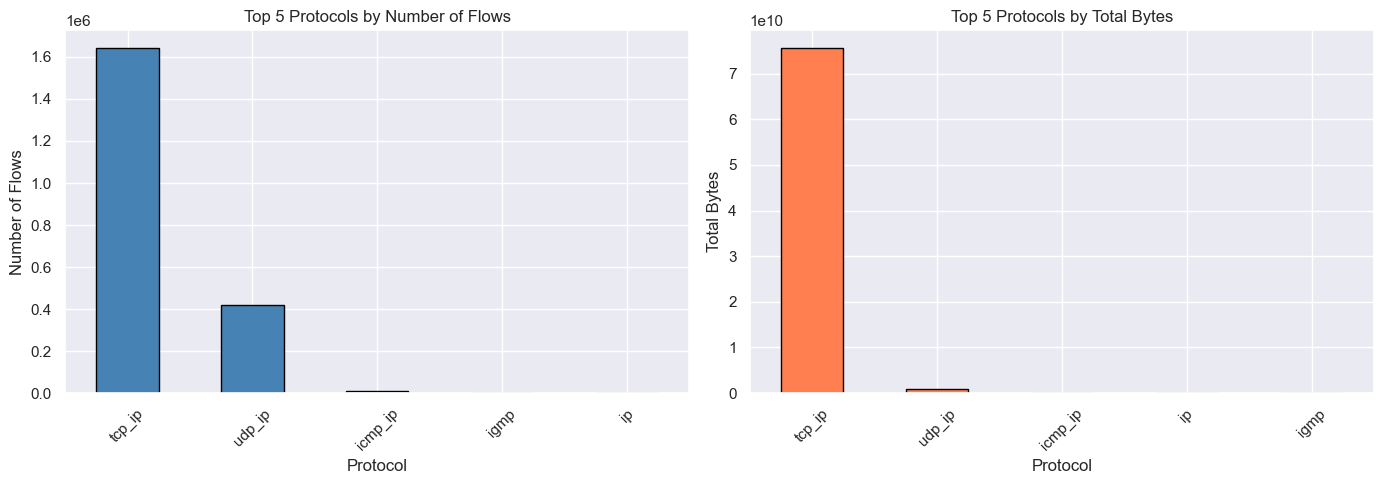

In [3]:
# ─── Q2: Top K Most Frequently Used Protocols ─────────────────────────────
K = 5   # configurable — change this to see more/fewer protocols

# Count by number of flows: tells us which protocols are most commonly used
protocol_counts = df['protocolName'].value_counts().head(K)
print(f'Top {K} protocols by number of flows:\n')
print(protocol_counts.to_string())

# Count by bytes: tells us which protocols consume the most bandwidth
# A protocol used rarely can still dominate bytes (e.g., large file transfers)
protocol_bytes = (df.groupby('protocolName')['totalBytes']
                    .sum()
                    .sort_values(ascending=False)
                    .head(K))
print(f'\nTop {K} protocols by traffic volume (bytes):\n')
print(protocol_bytes.to_string())

# ── Visualisation ─────────────────────────────────────────────────────────
# Side-by-side: flow count vs byte volume — shows if a protocol is
# frequent but lightweight, or rare but data-heavy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

protocol_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title(f'Top {K} Protocols by Number of Flows')
axes[0].set_xlabel('Protocol')
axes[0].set_ylabel('Number of Flows')
axes[0].tick_params(axis='x', rotation=45)

protocol_bytes.plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title(f'Top {K} Protocols by Total Bytes')
axes[1].set_xlabel('Protocol')
axes[1].set_ylabel('Total Bytes')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Q3 — Top 10 Most Active Source and Destination IPs
**Metric chosen: Total Bytes** — bytes is the most meaningful measure of traffic volume because it captures actual bandwidth consumption, not just connection frequency. An IP that opens 1000 tiny flows may use less bandwidth than one with 10 large file transfers.

**📊 Graph placement:** Side-by-side horizontal bar charts (source IPs left, destination IPs right) go here.

Top 10 Source IPs by total bytes:
 source
192.168.2.109    7369281030
192.168.1.101    6353065591
192.168.2.112    5759816514
192.168.1.103    5392234742
192.168.2.107    4861094682
192.168.2.113    4811521438
192.168.4.118    4006130354
192.168.4.121    3749783991
192.168.1.102    3719467167
192.168.2.110    3642212173

Top 10 Destination IPs by total bytes:
 destination
192.168.5.122      11944165221
69.84.133.138       5756927404
95.154.240.242      3989071044
68.178.178.97       2874806313
203.73.24.75        2123362825
79.125.17.124       1324802957
68.178.178.33       1255176342
91.190.170.71       1097473571
72.32.84.3           805065497
195.189.143.147      768644706


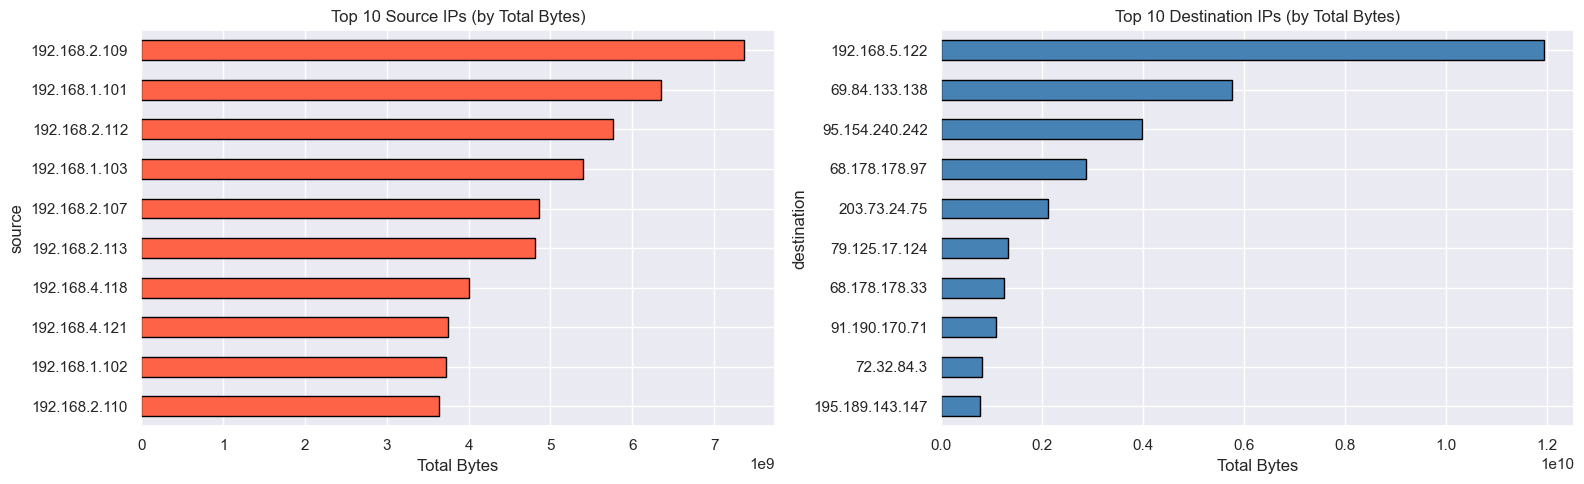


Top Source IPs by number of flows:
 source
192.168.5.122    268267
192.168.2.107    208379
192.168.4.118    135374
192.168.1.101    116292
192.168.4.121    105454
192.168.1.105    101359
192.168.2.109     99183
192.168.3.116     97241
192.168.2.110     90658
192.168.3.115     88915

Top Destination IPs by number of flows:
 destination
198.164.30.2       232409
192.168.5.122      199437
203.73.24.75       193200
125.6.164.51       106826
67.220.214.50       49298
202.210.143.140     36189
82.98.86.183        25214
95.211.98.12        25095
209.112.44.10       21824
62.140.213.243      20509


In [4]:
# ─── Q3: Top 10 Most Active Source & Destination IPs ──────────────────────
# Metric: total bytes (source + destination combined)
# We group by IP and sum totalBytes to get per-IP bandwidth consumption.

top_src = (df.groupby('source')['totalBytes']
             .sum()
             .sort_values(ascending=False)
             .head(10))

top_dst = (df.groupby('destination')['totalBytes']
             .sum()
             .sort_values(ascending=False)
             .head(10))

print('Top 10 Source IPs by total bytes:\n', top_src.to_string())
print('\nTop 10 Destination IPs by total bytes:\n', top_dst.to_string())

# ── Visualisation ─────────────────────────────────────────────────────────
# Horizontal bar charts are easier to read for IP addresses (long strings)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_src.plot(kind='barh', ax=axes[0], color='tomato', edgecolor='black')
axes[0].set_title('Top 10 Source IPs (by Total Bytes)')
axes[0].set_xlabel('Total Bytes')
axes[0].invert_yaxis()   # highest value at top

top_dst.plot(kind='barh', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Top 10 Destination IPs (by Total Bytes)')
axes[1].set_xlabel('Total Bytes')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# ── Secondary metric: by flow count ───────────────────────────────────────
# An IP active in many flows but with low bytes could be a scanner
# (lots of tiny probe packets) — useful to cross-reference
top_src_flows = df['source'].value_counts().head(10)
top_dst_flows = df['destination'].value_counts().head(10)
print('\nTop Source IPs by number of flows:\n', top_src_flows.to_string())
print('\nTop Destination IPs by number of flows:\n', top_dst_flows.to_string())

### Q4 — Average Packet Size
Average packet size = total bytes / total packets per flow.  
We also compare mean vs median — if they diverge significantly, the mean is not representative (distribution is skewed).

**📊 Graph placement:** Histogram with KDE overlay, mean and median vertical lines go here.

Mean packet size   : 315.79 bytes
Median packet size : 195.38 bytes
Std deviation      : 266.07 bytes

⚠ Mean and median differ by >10% — mean is NOT representative.
  The distribution is right-skewed: large file transfers or
  attack traffic are pulling the mean above the typical value.


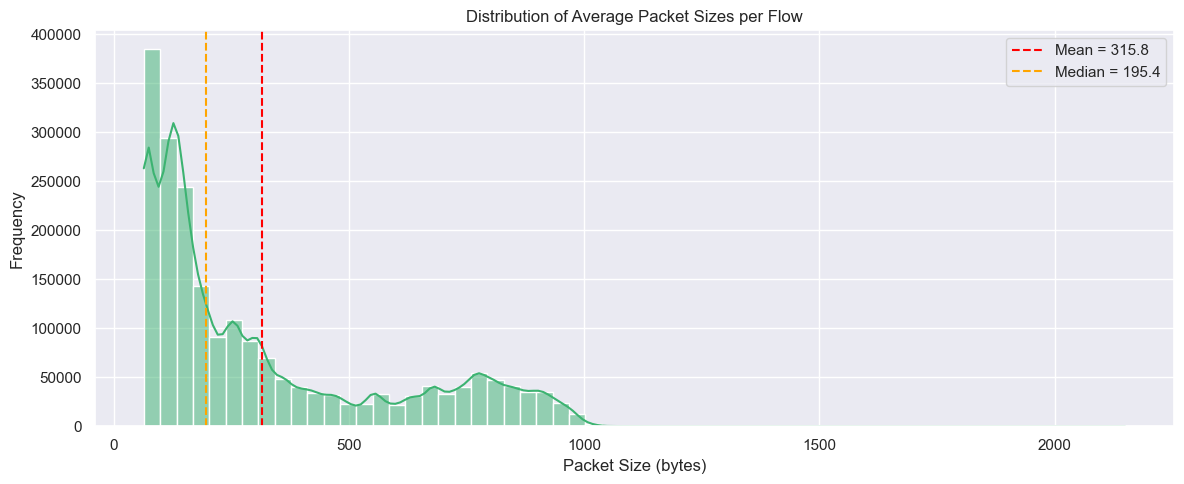

In [5]:
# ─── Q4: Average Packet Size ──────────────────────────────────────────────
# We compute avg packet size per flow (not globally) to avoid one high-volume
# flow drowning out the rest of the dataset.
# replace(0, NaN) prevents division-by-zero for flows with 0 packets.
df['avg_packet_size'] = df['totalBytes'] / df['totalPackets'].replace(0, np.nan)

mean_pkt   = df['avg_packet_size'].mean()
median_pkt = df['avg_packet_size'].median()
std_pkt    = df['avg_packet_size'].std()

print(f'Mean packet size   : {mean_pkt:.2f} bytes')
print(f'Median packet size : {median_pkt:.2f} bytes')
print(f'Std deviation      : {std_pkt:.2f} bytes')
print()

# If mean and median differ by more than 10%, the distribution is skewed.
# Skew is common in network traffic: most packets are small (ACKs, DNS),
# but rare large transfers pull the mean upward.
if abs(mean_pkt - median_pkt) / median_pkt > 0.1:
    print('⚠ Mean and median differ by >10% — mean is NOT representative.')
    print('  The distribution is right-skewed: large file transfers or')
    print('  attack traffic are pulling the mean above the typical value.')
else:
    print('✔ Mean and median are close — mean is reasonably representative.')

# ── Visualisation ─────────────────────────────────────────────────────────
# KDE (kernel density estimate) smooths the histogram to show the distribution
# shape. The two vertical lines show where mean and median fall.
plt.figure()
sns.histplot(df['avg_packet_size'].dropna(), bins=60, kde=True, color='mediumseagreen')
plt.axvline(mean_pkt,   color='red',    linestyle='--', label=f'Mean = {mean_pkt:.1f}')
plt.axvline(median_pkt, color='orange', linestyle='--', label=f'Median = {median_pkt:.1f}')
plt.title('Distribution of Average Packet Sizes per Flow')
plt.xlabel('Packet Size (bytes)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Q5 — Top 3 Most Frequent Source–Destination Pairs
Pairs with very high flow counts between them may indicate persistent connections, automated services, or potential data exfiltration tunnels.

In [6]:
# ─── Q5: Top 3 Most Frequent Source–Destination Pairs ─────────────────────
# We group by (source, destination) pair and count the number of flows.
# A very high count between two specific IPs warrants further investigation —
# it could be a legitimate service (e.g., backup) or a covert channel.
pair_counts = (df.groupby(['source', 'destination'])
                 .size()
                 .reset_index(name='flow_count')
                 .sort_values('flow_count', ascending=False)
                 .head(3))

print('Top 3 most frequent source–destination pairs:\n')
print(pair_counts.to_string(index=False))

Top 3 most frequent source–destination pairs:

       source  destination  flow_count
192.168.5.122 198.164.30.2      232409
192.168.2.107 125.6.164.51       58744
192.168.3.115 203.73.24.75       43785


### Q6 — Consistent Communication Across Time Windows
**Time window definition:** 1 hour.  
**Justification:** Hourly windows balance granularity (fine enough to detect periodic patterns) against noise (wide enough to not fragment legitimate sessions). An IP consistently appearing across many hourly windows is likely an always-on service or an automated agent.

**Threshold:** IPs active in ≥50% of all hourly windows are classified as *consistent communicators*.

In [7]:
# ─── Q6: Consistent Communication Across Time Windows ─────────────────────
# Floor each flow's start time to the nearest hour to assign it to a window.
# e.g., 14:37:22 → 14:00:00
df['hour_window'] = df['startDateTime'].dt.floor('h')

# Count how many distinct hourly windows each source IP appears in.
# An IP in many windows = persistent/scheduled traffic.
ip_window_counts = (df.groupby('source')['hour_window']
                      .nunique()
                      .reset_index(name='active_windows')
                      .sort_values('active_windows', ascending=False))

total_windows = df['hour_window'].nunique()
print(f'Total 1-hour windows in dataset: {total_windows}')

# Threshold: present in ≥50% of all windows = "consistent communicator"
# This catches IPs that are active throughout the day, not just occasional
threshold = total_windows * 0.5
consistent_ips = ip_window_counts[ip_window_counts['active_windows'] >= threshold]

print(f'\nIPs active in ≥50% of all time windows ({threshold:.0f}+ windows):\n')
print(consistent_ips.head(15).to_string(index=False))

Total 1-hour windows in dataset: 146

IPs active in ≥50% of all time windows (73+ windows):

       source  active_windows
192.168.3.115             145
192.168.3.114             145
192.168.2.113             145
192.168.2.112             145
192.168.1.101             145
192.168.2.107             145
192.168.1.105             145
192.168.1.104             145
192.168.2.111             145
192.168.2.110             145
192.168.2.109             145
192.168.2.108             145
192.168.5.122             145
192.168.1.102             145
192.168.1.103             145


### Q7 — Traffic Volume Spikes Over Time
**Method:** Z-score threshold — a window is a *spike* if its byte volume exceeds mean + 2σ.  
**Why 2σ?** Under a normal distribution, only ~2.3% of values fall above this threshold, making it a principled statistical cut-off. Spikes could indicate DDoS attacks, bulk data transfers, malware propagation, or backup jobs.

**📊 Graph placement:** Time-series line chart with spike threshold line and highlighted spike points goes here.

Spike threshold (mean + 2σ) : 2,060,114,179 bytes
Number of spike windows     : 2

        hour_window  total_bytes
2010-06-13 10:00:00   2356769418
2010-06-15 16:00:00   7720046056


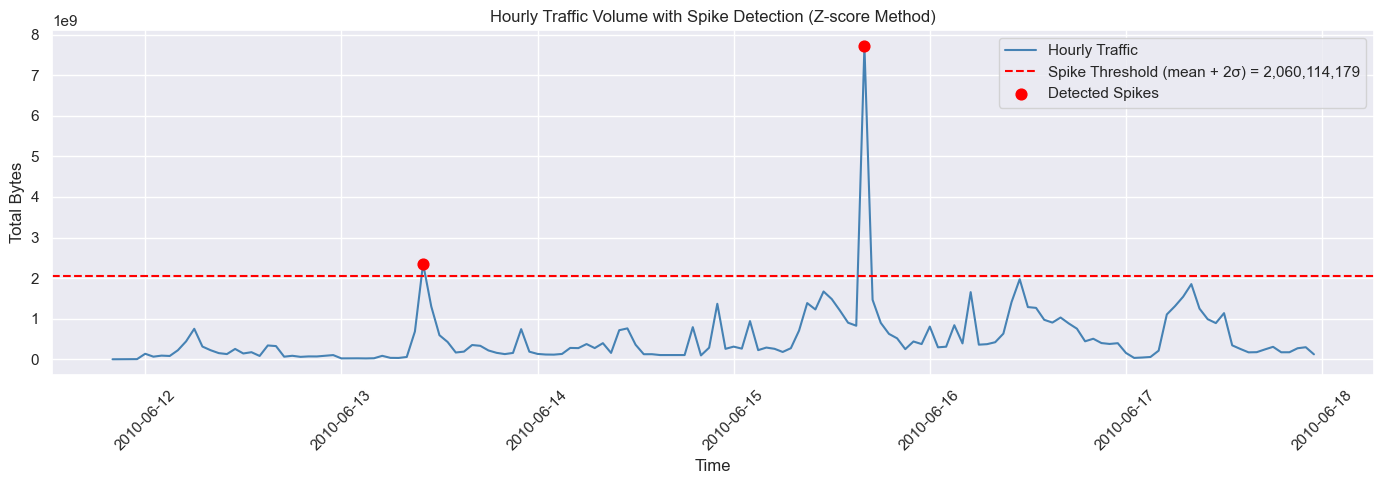

In [8]:
# ─── Q7: Traffic Volume Spikes Over Time ──────────────────────────────────
# Aggregate total bytes per hour window to create a time series.
hourly_bytes = (df.groupby('hour_window')['totalBytes']
                  .sum()
                  .reset_index(name='total_bytes'))

# Compute spike threshold using Z-score method:
# Spike = any window whose volume exceeds mean + 2 standard deviations
mean_vol  = hourly_bytes['total_bytes'].mean()
std_vol   = hourly_bytes['total_bytes'].std()
threshold = mean_vol + 2 * std_vol

hourly_bytes['is_spike'] = hourly_bytes['total_bytes'] > threshold
spikes = hourly_bytes[hourly_bytes['is_spike']]

print(f'Spike threshold (mean + 2σ) : {threshold:,.0f} bytes')
print(f'Number of spike windows     : {len(spikes)}')
print()
print(spikes[['hour_window', 'total_bytes']].to_string(index=False))

# ── Visualisation ─────────────────────────────────────────────────────────
# Line chart shows the full time series; red dashed line is the threshold;
# red dots mark windows classified as spikes.
plt.figure(figsize=(14, 5))
plt.plot(hourly_bytes['hour_window'], hourly_bytes['total_bytes'],
         label='Hourly Traffic', color='steelblue')
plt.axhline(threshold, color='red', linestyle='--',
            label=f'Spike Threshold (mean + 2σ) = {threshold:,.0f}')
plt.scatter(spikes['hour_window'], spikes['total_bytes'],
            color='red', zorder=5, label='Detected Spikes', s=60)
plt.title('Hourly Traffic Volume with Spike Detection (Z-score Method)')
plt.xlabel('Time')
plt.ylabel('Total Bytes')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Q8 — Variance of Packet Sizes
Variance measures the spread of packet sizes across all flows.
- **High variance** → mixed traffic types (file transfers + ACKs + DNS + video) or presence of attack traffic (DDoS packets are often tiny)
- **Low variance** → uniform traffic (VoIP with fixed 160-byte packets, or a filtered dataset)

Variance of packet sizes: 70,795.81

Low variance detected.
Possible reasons:
  • Uniform traffic type (e.g., VoIP uses fixed-size RTP packets)
  • Dataset may be preprocessed or filtered to a single traffic class


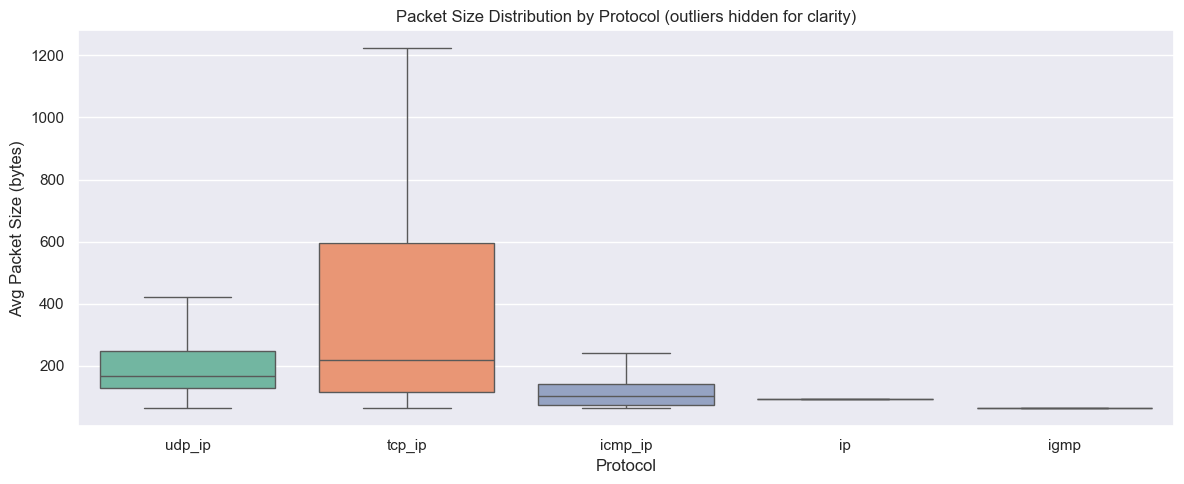

In [9]:
# ─── Q8: Variance of Packet Sizes ─────────────────────────────────────────
# Variance = average squared deviation from the mean.
# High variance in network traffic typically signals mixed workloads or attacks.
variance = df['avg_packet_size'].var()
print(f'Variance of packet sizes: {variance:,.2f}')
print()

if variance > 100000:
    print('High variance detected.')
    print('Possible reasons:')
    print('  • Mix of large file transfers and small control/ACK packets')
    print('  • Presence of attack traffic (DDoS often uses tiny flooding packets)')
    print('  • Multiple application types (video streaming, DNS, HTTP) coexisting')
    print('  • Data exfiltration: large outbound payloads alongside normal small flows')
else:
    print('Low variance detected.')
    print('Possible reasons:')
    print('  • Uniform traffic type (e.g., VoIP uses fixed-size RTP packets)')
    print('  • Dataset may be preprocessed or filtered to a single traffic class')

# ── Boxplot to visualise spread by protocol ───────────────────────────────
# Shows whether some protocols have more variable packet sizes than others
top_protos = df['protocolName'].value_counts().head(5).index
df_top = df[df['protocolName'].isin(top_protos)]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_top, x='protocolName', y='avg_packet_size',
            palette='Set2', showfliers=False)
plt.title('Packet Size Distribution by Protocol (outliers hidden for clarity)')
plt.xlabel('Protocol')
plt.ylabel('Avg Packet Size (bytes)')
plt.tight_layout()
plt.show()

---
## Section 2: Traffic Estimation Using Sublinear Space

In real-world network monitoring, storing exact counts for millions of IP addresses is infeasible.  
This section implements three **probabilistic data structures** that approximate results using a fraction of the memory:

| Structure | Task | Error type |
|---|---|---|
| **HyperLogLog** | Count distinct IPs | ~1–2% cardinality error |
| **Count-Min Sketch** | Find heavy-hitter IPs | Slight over-estimate, never under |
| **Bloom Filter** | Test IP membership | False positives only, never false negatives |

### 2a — HyperLogLog: Estimating Distinct IP Addresses

**Idea:** Hash each IP to a binary string. Track the maximum number of *leading zeros* seen across all hashes. A longer run of leading zeros is statistically more likely to occur when more distinct values have been seen — so we use it as a proxy for cardinality.

Multiple registers (buckets) are used and their estimates are combined via a harmonic mean to reduce variance.

In [10]:
# ─── 2a: HyperLogLog — Estimate Distinct IPs ─────────────────────────────

class HyperLogLog:
    """
    HyperLogLog probabilistic cardinality estimator.

    Core idea:
      - Hash each element to a 32-bit integer.
      - Use the first 'b' bits to select a register (bucket).
      - Count leading zeros in the remaining bits — more zeros = rarer event.
      - Each register stores the maximum leading-zero count seen so far.
      - Final estimate = alpha * m^2 / harmonic_mean(2^(-register values))

    Parameters:
      b : int — number of bits for register indexing (default 10)
              m = 2^b registers; higher b = more memory, more accuracy
    """
    def __init__(self, b=10):
        self.b = b
        self.m = 2 ** b                  # total number of registers
        self.registers = [0] * self.m    # initialised to 0 (no elements seen yet)

        # Alpha: bias correction constant — derived mathematically from register count
        # Prevents systematic over/underestimation
        if self.m >= 128:
            self.alpha = 0.7213 / (1 + 1.079 / self.m)
        elif self.m == 64:
            self.alpha = 0.709
        elif self.m == 32:
            self.alpha = 0.697
        else:
            self.alpha = 0.5

    def _hash(self, value):
        """Map any string to a 32-bit integer using MD5. Deterministic."""
        return int(hashlib.md5(value.encode()).hexdigest(), 16) & 0xFFFFFFFF

    def add(self, value):
        """
        Insert a value into the HyperLogLog.
        Step 1: hash the value to a 32-bit integer.
        Step 2: top b bits → which register to update.
        Step 3: remaining bits → count leading zeros (position of first 1-bit).
        Step 4: update that register if this count is a new maximum.
        """
        h = self._hash(str(value))
        register_idx = h >> (32 - self.b)               # top b bits = register index
        remaining    = h & ((1 << (32 - self.b)) - 1)   # lower (32-b) bits
        # leading zeros: how many bits until the first '1' from the left
        leading_zeros = (32 - self.b) - remaining.bit_length() + 1
        self.registers[register_idx] = max(self.registers[register_idx], leading_zeros)

    def count(self):
        """
        Estimate the number of distinct elements added so far.
        Uses harmonic mean of 2^(-register) values across all registers.
        Applies small-range correction when many registers are still 0
        (early in the stream, before enough hashes are seen).
        """
        Z        = sum(2 ** (-r) for r in self.registers)   # harmonic mean denominator
        estimate = self.alpha * (self.m ** 2) / Z

        # Small-range correction: if estimate is small relative to m, use
        # linear counting (count of zero registers) which is more accurate
        if estimate <= 2.5 * self.m:
            zeros = self.registers.count(0)
            if zeros > 0:
                estimate = self.m * math.log(self.m / zeros)

        return int(estimate)


# ── Combine source and destination IPs into one stream ────────────────────
# We want total distinct IPs across the entire network, not just sources
all_ips = pd.concat([df['source'], df['destination']]).dropna().astype(str)

# ── Feed all IPs into HyperLogLog ─────────────────────────────────────────
hll = HyperLogLog(b=10)   # b=10 → 1024 registers, ~1.6% expected error
for ip in all_ips:
    hll.add(ip)
hll_estimate = hll.count()

# ── Exact count using a Python set (stores every unique IP) ───────────────
# This is the ground truth — but uses O(n) memory
exact_ip_set  = set(all_ips)
exact_count   = len(exact_ip_set)

# ── Error rate ────────────────────────────────────────────────────────────
error_rate = abs(hll_estimate - exact_count) / exact_count * 100
print(f'HyperLogLog estimate  : {hll_estimate:,}')
print(f'Exact count (set)     : {exact_count:,}')
print(f'Error rate            : {error_rate:.2f}%')
print()
if error_rate <= 10:
    print('✔ Error rate is within the 10% threshold.')
else:
    print('⚠ Error rate exceeds 10% — try increasing b to 12 or 14.')

# ── Memory comparison (FIX: measure full deep size, not just list shell) ──
# sys.getsizeof on a list only counts the list object overhead, not its contents.
# We add element sizes manually for an accurate comparison.
hll_mem   = sys.getsizeof(hll.registers) + sum(sys.getsizeof(r) for r in hll.registers)
exact_mem = sys.getsizeof(exact_ip_set)  + sum(sys.getsizeof(ip) for ip in exact_ip_set)

print(f'\nHyperLogLog memory : {hll_mem:,} bytes  ({hll_mem/1024:.1f} KB)')
print(f'Exact set memory   : {exact_mem:,} bytes ({exact_mem/1024/1024:.1f} MB)')
print(f'Memory saved       : {exact_mem / hll_mem:.0f}x')

HyperLogLog estimate  : 35,611
Exact count (set)     : 34,801
Error rate            : 2.33%

✔ Error rate is within the 10% threshold.

HyperLogLog memory : 36,920 bytes  (36.1 KB)
Exact set memory   : 4,255,621 bytes (4.1 MB)
Memory saved       : 115x


### 2b — Count-Min Sketch: Identifying Heavy Hitter Destination IPs

**Idea:** A 2D array of counters with `depth` rows, each using a different hash function. To increment an item, we add 1 to one counter per row. To query, we return the *minimum* across all rows — this minimum is guaranteed to never underestimate the true count, and collisions only cause overestimation.

**📊 Graph placement:** Bar chart comparing exact vs CMS-estimated counts for top 10 destination IPs goes here.

Count-Min Sketch vs Exact Counts — Top 10 Destination IPs:

 destination_ip  exact  cms_estimate  error_%
   198.164.30.2 232409        232475     0.03
  192.168.5.122 199437        199504     0.03
   203.73.24.75 193200        193226     0.01
   125.6.164.51 106826        106887     0.06
  67.220.214.50  49298         49366     0.14
202.210.143.140  36189         36222     0.09
   82.98.86.183  25214         25252     0.15
   95.211.98.12  25095         25141     0.18
  209.112.44.10  21824         21873     0.22
 62.140.213.243  20509         20561     0.25

Max error  : 0.25%
Mean error : 0.12%

✔ All estimates within 10% error threshold (max: 0.25%)


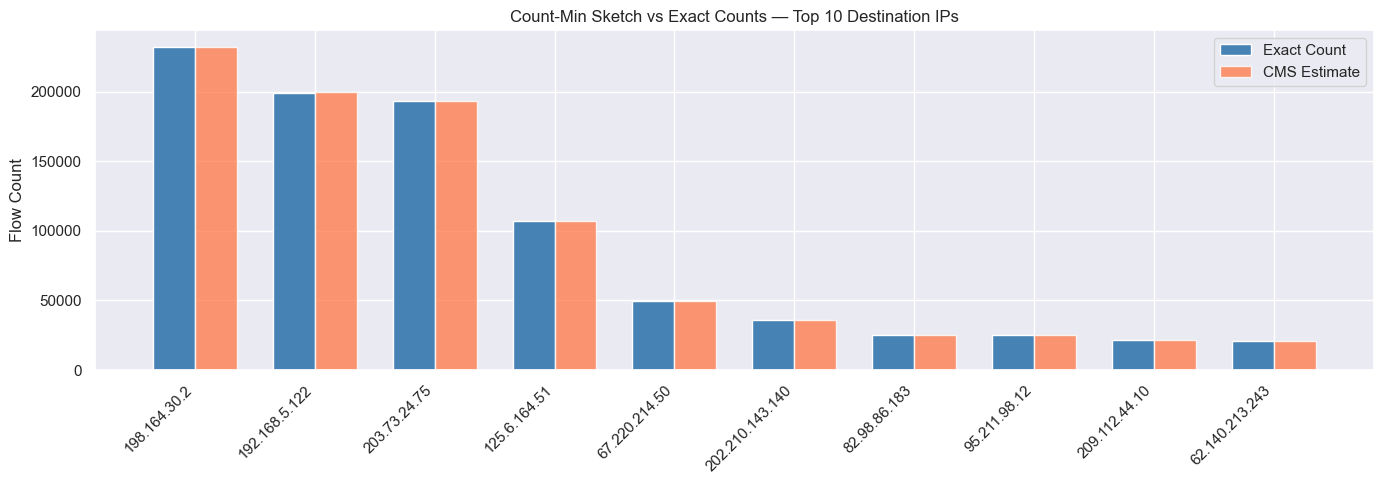

In [11]:
# ─── 2b: Count-Min Sketch — Frequent Destination IPs ─────────────────────

class CountMinSketch:
    """
    Count-Min Sketch for approximate frequency counting.

    Structure: a 2D array of size (depth × width).
      - depth = number of independent hash functions
      - width = number of counter buckets per hash function

    On add(item): increment table[i][hash_i(item)] for each row i.
    On estimate(item): return min(table[i][hash_i(item)]) across all rows.

    The min is taken because hash collisions can only ADD to counters (inflate);
    the true count is always ≤ every cell touched by an item, so the min
    is the tightest upper bound we can compute.

    Memory: depth × width × 4 bytes (int32) — fixed, regardless of data size.
    """
    def __init__(self, width=2000, depth=7):
        self.width = width   # more columns → fewer collisions → less error
        self.depth = depth   # more rows → min is tighter → less error
        # 2D counter array — all zeros initially
        self.table = np.zeros((depth, width), dtype=np.int32)
        # Each row uses a different seed to generate a different hash function
        # Multiply by a large prime to spread seeds evenly across the int space
        self.seeds = [i * 2654435761 % (2**31) for i in range(1, depth + 1)]

    def _hashes(self, item):
        """
        Generate 'depth' hash positions for a given item.
        Each row uses a different seed prepended to the item before hashing,
        ensuring independence between rows.
        """
        return [
            int(hashlib.md5(f'{seed}{item}'.encode()).hexdigest(), 16) % self.width
            for seed in self.seeds
        ]

    def add(self, item, count=1):
        """Increment the counter in each row at that row's hash position."""
        for i, col in enumerate(self._hashes(str(item))):
            self.table[i][col] += count

    def estimate(self, item):
        """
        Return the minimum counter value across all rows.
        This is an upper bound on the true frequency (may over-estimate
        due to hash collisions, but never under-estimates).
        """
        return min(
            self.table[i][col]
            for i, col in enumerate(self._hashes(str(item)))
        )


# ── Build the sketch from all destination IPs ─────────────────────────────
# We process the stream once — O(n) time, O(width × depth) space
cms = CountMinSketch(width=2000, depth=7)
for ip in df['destination'].dropna().astype(str):
    cms.add(ip)

# ── Exact counts for comparison (uses a full dictionary) ─────────────────
exact_dst_counts = df['destination'].value_counts()

# ── Compare top 10 heavy hitters ─────────────────────────────────────────
top10_ips = exact_dst_counts.head(10).index.tolist()

results = []
for ip in top10_ips:
    exact  = exact_dst_counts[ip]
    approx = cms.estimate(ip)
    err    = abs(approx - exact) / exact * 100 if exact > 0 else 0
    results.append({'destination_ip': ip, 'exact': exact,
                    'cms_estimate': approx, 'error_%': round(err, 2)})

results_df = pd.DataFrame(results)
print('Count-Min Sketch vs Exact Counts — Top 10 Destination IPs:\n')
print(results_df.to_string(index=False))

max_err  = results_df['error_%'].max()
mean_err = results_df['error_%'].mean()
print(f'\nMax error  : {max_err:.2f}%')
print(f'Mean error : {mean_err:.2f}%')

# ── Error threshold check ─────────────────────────────────────────────────
if max_err <= 10:
    print(f'\n✔ All estimates within 10% error threshold (max: {max_err:.2f}%)')
else:
    print(f'\n⚠ Some estimates exceed 10% error (max: {max_err:.2f}%) — try increasing width')

# ── Visualisation ─────────────────────────────────────────────────────────
# Side-by-side bars: exact vs CMS estimate for each of the top 10 IPs
x = range(len(results_df))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar([i - width/2 for i in x], results_df['exact'],       width, label='Exact Count',    color='steelblue')
ax.bar([i + width/2 for i in x], results_df['cms_estimate'], width, label='CMS Estimate',   color='coral', alpha=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels(results_df['destination_ip'], rotation=45, ha='right')
ax.set_title('Count-Min Sketch vs Exact Counts — Top 10 Destination IPs')
ax.set_ylabel('Flow Count')
ax.legend()
plt.tight_layout()
plt.show()

### 2c — Bloom Filter: Efficient IP Blocklist Membership Testing

**Idea:** A bit array of size `m`, initially all zeros. To insert an item, set bits at `k` hash-derived positions to 1. To query, check if *all* `k` positions are 1.
- If any bit is 0 → item is **definitely not** in the set (no false negatives)
- If all bits are 1 → item is **probably** in the set (may be a false positive)

Perfect for IP blocklists: we never miss a known-bad IP, and rare false alarms are acceptable.

In [12]:
# ─── 2c: Bloom Filter — IP Blocklist Membership Testing ──────────────────

class BloomFilter:
    """
    Bloom Filter for approximate set membership testing.

    The bit array size and number of hash functions are computed from
    the expected capacity and desired false positive rate using the
    optimal formulas:
      m = -(n * ln(p)) / ln(2)^2    [bit array size]
      k = (m / n) * ln(2)           [number of hash functions]

    Guarantees:
      - Zero false negatives (if item was inserted, check() always returns True)
      - False positive rate ≈ target error_rate
    """
    def __init__(self, capacity=100000, error_rate=0.01):
        # Optimal bit array size given capacity and desired false positive rate
        self.size = int(-(capacity * math.log(error_rate)) / (math.log(2) ** 2))
        # Optimal number of hash functions
        self.num_hashes = int((self.size / capacity) * math.log(2))
        # bitarray is a compact C-backed bit array — much more memory-efficient
        # than a Python list of booleans
        self.bit_array = bitarray(self.size)
        self.bit_array.setall(0)   # initialise all bits to 0
        print('Bloom Filter initialised:')
        print(f'  Bit array size : {self.size:,} bits ({self.size // 8 / 1024:.1f} KB)')
        print(f'  Hash functions : {self.num_hashes}')
        print(f'  Target FP rate : {error_rate * 100:.1f}%')

    def _hashes(self, item):
        """
        Generate k bit positions using double hashing:
          position_i = (h1 + i * h2) % size
        Using two independent hashes (MD5 + SHA1) avoids needing k separate
        hash functions while maintaining good distribution.
        """
        h1 = int(hashlib.md5(str(item).encode()).hexdigest(),  16)
        h2 = int(hashlib.sha1(str(item).encode()).hexdigest(), 16)
        return [(h1 + i * h2) % self.size for i in range(self.num_hashes)]

    def add(self, item):
        """Insert item: set all k hash-mapped bit positions to 1."""
        for pos in self._hashes(item):
            self.bit_array[pos] = 1

    def check(self, item):
        """
        Query membership:
          True  → all k bits are 1 → item PROBABLY in set
          False → at least one bit is 0 → item DEFINITELY NOT in set
        """
        return all(self.bit_array[pos] for pos in self._hashes(item))


# ── Build blocklist from all seen source IPs ──────────────────────────────
bf = BloomFilter(capacity=100000, error_rate=0.01)
seen_ips = df['source'].dropna().astype(str).unique()
for ip in seen_ips:
    bf.add(ip)

# ── Exact membership check using a Python set ─────────────────────────────
exact_set = set(seen_ips)

# ── Test 1: Known IPs — must all return True (no false negatives allowed) ─
test_known = list(seen_ips[:50])

# ── Test 2: Unseen IPs — use the 192.0.2.x reserved documentation range ──
# 192.0.2.0/24 is reserved (RFC 5737) and will never appear in real traffic.
# This guarantees our 'unknown' test IPs are truly absent from the dataset.
# FIX: Original used 10.255.x.x which could appear in real traffic.
all_seen_set = exact_set | set(df['destination'].dropna().astype(str))
test_unknown = [ip for ip in [f'192.0.2.{i}' for i in range(100)]
                if ip not in all_seen_set][:50]

fn_count = 0
fp_count = 0

for ip in test_known:
    if not bf.check(ip):
        fn_count += 1   # false negative: should NEVER happen

for ip in test_unknown:
    if bf.check(ip) and ip not in exact_set:
        fp_count += 1   # false positive: acceptable at low rates

fp_rate = fp_count / len(test_unknown) * 100 if test_unknown else 0
print(f'\nResults on {len(test_known)} known + {len(test_unknown)} unknown IPs:')
print(f'  False negatives : {fn_count}  (must always be 0)')
print(f'  False positives : {fp_count}/{len(test_unknown)} = {fp_rate:.1f}%')

# ── Memory comparison ─────────────────────────────────────────────────────
bf_mem    = bf.size // 8   # bits → bytes
exact_mem = sum(sys.getsizeof(ip) for ip in exact_set)
print(f'\n  Bloom Filter memory : {bf_mem / 1024:.1f} KB')
print(f'  Exact set memory    : {exact_mem / 1024:.1f} KB')
print(f'  Memory reduction    : {exact_mem / bf_mem:.1f}x')

Bloom Filter initialised:
  Bit array size : 958,505 bits (117.0 KB)
  Hash functions : 6
  Target FP rate : 1.0%

Results on 50 known + 50 unknown IPs:
  False negatives : 0  (must always be 0)
  False positives : 0/50 = 0.0%

  Bloom Filter memory : 117.0 KB
  Exact set memory    : 150.1 KB
  Memory reduction    : 1.3x


---
## Section 3: Advanced Anomaly Detection

We now use the statistics computed in Section 1 as baselines to flag anomalous behaviour.
Three complementary approaches are used:
- **3a** — Statistical thresholds (Z-score)
- **3b** — Behavioural analysis (burst detection, fan-in)
- **3c** — Suspicious communication patterns (long connections, multi-protocol)

### 3a — Statistical Traffic Analysis

**Method:** Z-score thresholding — flag any flow/IP where a metric exceeds mean ± 2σ.  
Z-score is scale-invariant: it works equally well whether packet sizes are in bytes or gigabytes.

**📊 Graph placement:** Hourly vs daily traffic bar charts go here (Section 3a, Q2).

In [13]:
# ─── 3a: Statistical Anomaly Thresholds ───────────────────────────────────

def flag_outliers(series, label, z_thresh=2.0):
    """
    Flag values in 'series' that are more than z_thresh standard deviations
    from the mean.

    BUG FIX: Original code computed z_scores on series.dropna() but then
    tried to index the original (longer) series — causing shape mismatch.
    Fix: work entirely on the clean (dropna) series throughout.

    Parameters:
        series   : pd.Series — numeric column to analyse
        label    : str       — display name for printing
        z_thresh : float     — Z-score threshold (default 2.0 = mean ± 2σ)

    Returns:
        pd.Series of outlier values
    """
    clean    = series.dropna()                    # remove NaN before stats
    mean     = clean.mean()
    std      = clean.std()
    z_scores = np.abs(stats.zscore(clean))        # z_scores aligned to 'clean'
    outliers = clean[z_scores > z_thresh]         # index 'clean', not 'series'

    print(f'\n[{label}]')
    print(f'  Mean              : {mean:,.2f}')
    print(f'  Std deviation     : {std:,.2f}')
    print(f'  Threshold range   : [{mean - z_thresh*std:,.2f}, {mean + z_thresh*std:,.2f}]')
    print(f'  Outlier flows     : {len(outliers):,}  ({len(outliers)/len(clean)*100:.2f}%)')
    return outliers

print('=' * 55)
print('STATISTICAL ANOMALY THRESHOLDS (Z-score > 2σ)')
print('=' * 55)

# Run outlier detection on four key metrics
# Each returns the set of flows that exceed the threshold for that metric
outlier_bytes   = flag_outliers(df['totalBytes'],              'Total Bytes per Flow')
outlier_packets = flag_outliers(df['totalPackets'],            'Total Packets per Flow')
outlier_pktsize = flag_outliers(df['avg_packet_size'],         'Avg Packet Size')
outlier_dur     = flag_outliers(df['duration'],                'Flow Duration (seconds)')

STATISTICAL ANOMALY THRESHOLDS (Z-score > 2σ)

[Total Bytes per Flow]
  Mean              : 36,950.06
  Std deviation     : 1,446,484.82
  Threshold range   : [-2,856,019.58, 2,929,919.69]
  Outlier flows     : 2,333  (0.11%)

[Total Packets per Flow]
  Mean              : 50.14
  Std deviation     : 1,632.60
  Threshold range   : [-3,215.06, 3,315.34]
  Outlier flows     : 2,208  (0.11%)

[Avg Packet Size]
  Mean              : 315.79
  Std deviation     : 266.07
  Threshold range   : [-216.36, 847.94]
  Outlier flows     : 124,988  (6.03%)

[Flow Duration (seconds)]
  Mean              : 48.99
  Std deviation     : 619.77
  Threshold range   : [-1,190.55, 1,288.53]
  Outlier flows     : 8,093  (0.39%)


In [14]:
# ── Protocol Distribution Anomalies ───────────────────────────────────────
# Rare protocols (< 1% of flows) are suspicious because legitimate enterprise
# networks typically run a predictable set of protocols. Unexpected protocols
# may indicate tunnelling, exfiltration tools, or misconfigured services.
proto_counts = df['protocolName'].value_counts(normalize=True) * 100
print('\nProtocol distribution (%):\n')
print(proto_counts.to_string())

rare_protocols  = proto_counts[proto_counts < 1.0]
rare_proto_flows = df[df['protocolName'].isin(rare_protocols.index)]

print(f'\nRare protocols (<1% of traffic): {list(rare_protocols.index)}')
print(f'Flows using rare protocols      : {len(rare_proto_flows):,}')

# ── Label validation ──────────────────────────────────────────────────────
# The dataset has a 'Label' column (Normal / Attack). We can check whether
# rare protocol flows are disproportionately labelled as attacks.
if 'Label' in df.columns and len(rare_proto_flows) > 0:
    print('\nLabel distribution for rare-protocol flows:')
    print(rare_proto_flows['Label'].value_counts().to_string())


Protocol distribution (%):

protocolName
tcp_ip      79.359469
udp_ip      20.237230
icmp_ip      0.396349
igmp         0.003717
ip           0.003186
ipv6icmp     0.000048

Rare protocols (<1% of traffic): ['icmp_ip', 'igmp', 'ip', 'ipv6icmp']
Flows using rare protocols      : 8,355

Label distribution for rare-protocol flows:
Label
Normal    8060
Attack     295


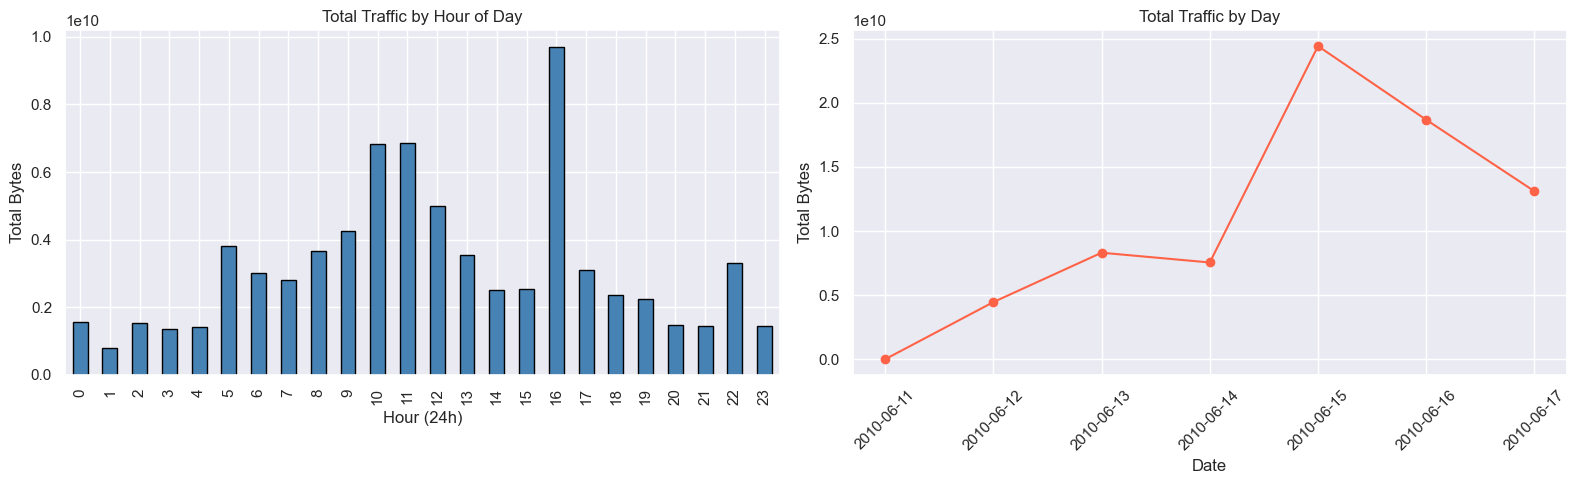

Peak traffic hour     : 16:00
Off-peak traffic hour : 1:00
Peak / off-peak ratio : 12.2x


In [15]:
# ── Hourly vs Daily Traffic Comparison ────────────────────────────────────
# Comparing hourly and daily patterns lets us identify temporal anomalies:
# - Traffic at unusual hours (e.g., 3am spike) may indicate automated attacks
# - A day with far higher traffic than others warrants investigation
df['hour']    = df['startDateTime'].dt.hour
df['date']    = df['startDateTime'].dt.date
df['weekday'] = df['startDateTime'].dt.day_name()

hourly_traffic = df.groupby('hour')['totalBytes'].sum()
daily_traffic  = df.groupby('date')['totalBytes'].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

hourly_traffic.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Total Traffic by Hour of Day')
axes[0].set_xlabel('Hour (24h)')
axes[0].set_ylabel('Total Bytes')

daily_traffic.plot(ax=axes[1], color='tomato', marker='o')
axes[1].set_title('Total Traffic by Day')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Total Bytes')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

peak_hour    = hourly_traffic.idxmax()
offpeak_hour = hourly_traffic.idxmin()
print(f'Peak traffic hour     : {peak_hour}:00')
print(f'Off-peak traffic hour : {offpeak_hour}:00')
print(f'Peak / off-peak ratio : {hourly_traffic[peak_hour]/hourly_traffic[offpeak_hour]:.1f}x')

In [16]:
# ── Flag High/Low Volume Source IPs ───────────────────────────────────────
# IPs with z_score > 2 are sending anomalously high traffic — potential
# exfiltrators or compromised hosts. IPs with z_score < -2 are unusually
# quiet — possibly reconnaissance hosts sending just probe packets.
ip_traffic = (df.groupby('source')['totalBytes']
                .sum()
                .reset_index(name='total_bytes'))

mean_t = ip_traffic['total_bytes'].mean()
std_t  = ip_traffic['total_bytes'].std()

ip_traffic['z_score'] = (ip_traffic['total_bytes'] - mean_t) / std_t
ip_traffic['flag']    = ip_traffic['z_score'].apply(
    lambda z: 'HIGH' if z > 2 else ('LOW' if z < -2 else 'Normal')
)

high_vol = ip_traffic[ip_traffic['flag'] == 'HIGH'].sort_values('total_bytes', ascending=False)
low_vol  = ip_traffic[ip_traffic['flag'] == 'LOW'].sort_values('total_bytes')

print(f'High-volume IPs (z > 2σ) : {len(high_vol)}')
print(high_vol.head(10).to_string(index=False))
print(f'\nLow-volume IPs  (z < -2σ): {len(low_vol)}')
print(low_vol.head(5).to_string(index=False))

# ── Label validation for high-volume IPs ─────────────────────────────────
if 'Label' in df.columns and len(high_vol) > 0:
    high_ip_labels = df[df['source'].isin(high_vol['source'])]['Label'].value_counts()
    print(f'\nLabel distribution for high-volume source IPs:')
    print(high_ip_labels.to_string())

High-volume IPs (z > 2σ) : 21
       source  total_bytes   z_score flag
192.168.2.109   7369281030 20.146311 HIGH
192.168.1.101   6353065591 17.356463 HIGH
192.168.2.112   5759816514 15.727798 HIGH
192.168.1.103   5392234742 14.718664 HIGH
192.168.2.107   4861094682 13.260509 HIGH
192.168.2.113   4811521438 13.124414 HIGH
192.168.4.118   4006130354 10.913348 HIGH
192.168.4.121   3749783991 10.209593 HIGH
192.168.1.102   3719467167 10.126363 HIGH
192.168.2.110   3642212173  9.914272 HIGH

Low-volume IPs  (z < -2σ): 0
Empty DataFrame
Columns: [source, total_bytes, z_score, flag]
Index: []

Label distribution for high-volume source IPs:
Label
Normal    1716238
Attack      61029


### 3b — Behavioural Analysis

Statistical thresholds catch *what* is unusual; behavioural analysis catches *how* an IP behaves over time.

**📊 Graph placement:** Fan-in bar chart (top DDoS target destinations) goes here.

In [17]:
# ─── 3b: Behavioural Analysis ─────────────────────────────────────────────

# ── 1. Burst Activity: sudden spikes after inactivity ─────────────────────
# Compute flow count per IP per hour window, then compare max vs mean.
# A spike_ratio of 5 means the busiest hour was 5x the average hour —
# consistent with a compromised host 'waking up' or a scheduled attack script.
ip_hourly = (df.groupby(['source', 'hour_window'])
               .size()
               .reset_index(name='flow_count'))

ip_behavior = (ip_hourly.groupby('source')['flow_count']
                         .agg(['mean', 'max', 'std', 'count'])
                         .reset_index())
ip_behavior.columns = ['source', 'mean_flows', 'max_flows', 'std_flows', 'active_windows']

# spike_ratio: ratio of peak activity to average activity
# High ratio + multiple windows = not just a one-off blip but a real pattern change
ip_behavior['spike_ratio'] = ip_behavior['max_flows'] / ip_behavior['mean_flows'].replace(0, 1)

suspicious_bursts = ip_behavior[
    (ip_behavior['spike_ratio']    > 5) &   # peak is 5x above average
    (ip_behavior['active_windows'] >= 3)    # seen in at least 3 windows (not a one-off)
].sort_values('spike_ratio', ascending=False)

print('IPs with sudden activity bursts (spike_ratio > 5, active in ≥3 windows):')
print(suspicious_bursts.head(10).to_string(index=False))

IPs with sudden activity bursts (spike_ratio > 5, active in ≥3 windows):
         source  mean_flows  max_flows   std_flows  active_windows  spike_ratio
  192.168.2.106  492.041379      21680 1967.208467             145    44.061335
131.202.240.209   15.242857        491   64.861376              70    32.211809
  192.168.1.105  699.027586      16272 1873.691091             145    23.278051
  192.168.2.110  625.227586      12762 1642.787763             145    20.411767
  192.168.2.113  534.020690      10127 1079.554676             145    18.963685
  192.168.5.123   11.756944        206   18.000484             144    17.521559
  192.168.3.116  670.627586       9303 1453.692449             145    13.872081
  192.168.2.109  684.020690       9464 1271.110836             145    13.835839
  192.168.2.111  424.075862       5833  774.466394             145    13.754614
  192.168.1.102  363.917241       4794  851.276856             145    13.173325


Fan-in threshold (mean + 2σ) : 8.6 distinct sources per window
Potential DDoS targets detected : 511

        hour_window   destination  distinct_sources
2010-06-15 07:00:00 192.168.2.107               468
2010-06-15 02:00:00 192.168.2.107               467
2010-06-15 04:00:00 192.168.2.107               436
2010-06-15 06:00:00 192.168.2.107               426
2010-06-15 05:00:00 192.168.2.107               411
2010-06-15 03:00:00 192.168.2.107               394
2010-06-15 08:00:00 192.168.2.107               388
2010-06-15 01:00:00 192.168.2.107               305
2010-06-14 22:00:00 192.168.2.107               183
2010-06-14 23:00:00 192.168.2.107               153


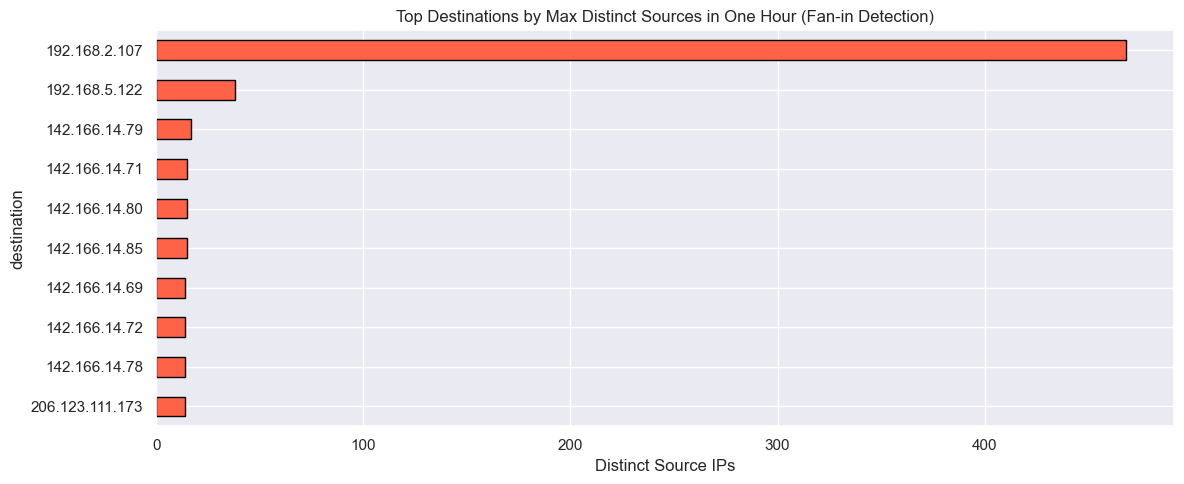

In [18]:
# ── 2. Fan-in Detection: many sources → one destination ───────────────────
# In a normal network, a destination receives traffic from a moderate number
# of sources. Sudden fan-in (many distinct sources all hitting the same target
# in one hour) is a classic DDoS signature.
fan_in = (df.groupby(['hour_window', 'destination'])['source']
            .nunique()
            .reset_index(name='distinct_sources'))

fan_in_mean  = fan_in['distinct_sources'].mean()
fan_in_std   = fan_in['distinct_sources'].std()
fan_in_thresh = fan_in_mean + 2 * fan_in_std   # 2σ above mean = abnormal fan-in

ddos_candidates = fan_in[
    fan_in['distinct_sources'] > fan_in_thresh
].sort_values('distinct_sources', ascending=False)

print(f'Fan-in threshold (mean + 2σ) : {fan_in_thresh:.1f} distinct sources per window')
print(f'Potential DDoS targets detected : {len(ddos_candidates)}')
print()
print(ddos_candidates.head(10).to_string(index=False))

# ── Visualisation ─────────────────────────────────────────────────────────
# Shows which destinations received traffic from the most distinct sources
# in any single hour — top targets are most likely under volumetric attack
top_targets = ddos_candidates.groupby('destination')['distinct_sources'].max().nlargest(10)
top_targets.plot(kind='barh', color='tomato', edgecolor='black')
plt.title('Top Destinations by Max Distinct Sources in One Hour (Fan-in Detection)')
plt.xlabel('Distinct Source IPs')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 3c — Suspicious Communication Patterns

**📊 Graph placement:** Boxplot of packet sizes by protocol (from Q8) can be referenced here.

In [19]:
# ─── 3c: Suspicious Communication Patterns ────────────────────────────────

# ── 1. Long-Duration Connections ──────────────────────────────────────────
# Most legitimate flows are short (seconds to minutes). A connection lasting
# hours suggests a persistent channel: backdoor, data exfiltration tunnel,
# or an unresponsive zombie session kept alive by keepalives.
# We use 3σ instead of 2σ here to be more conservative — we want only the
# truly extreme outliers, not just above-average flows.
dur_mean   = df['duration'].mean()
dur_std    = df['duration'].std()
dur_thresh = dur_mean + 3 * dur_std

long_connections = df[df['duration'] > dur_thresh][
    ['source', 'destination', 'protocolName', 'duration',
     'totalBytes', 'totalPackets', 'Label']
].sort_values('duration', ascending=False)

print(f'Duration threshold (mean + 3σ) : {dur_thresh:.1f}s ({dur_thresh/3600:.2f} hrs)')
print(f'Long-duration flows detected   : {len(long_connections):,}')
print()
print(long_connections.head(10).to_string(index=False))

Duration threshold (mean + 3σ) : 1908.3s (0.53 hrs)
Long-duration flows detected   : 7,628

       source     destination protocolName  duration  totalBytes  totalPackets  Label
192.168.1.101 255.255.255.255       udp_ip   49140.0      163332          1047 Normal
192.168.1.101   192.168.1.255       udp_ip   49140.0      163332          1047 Normal
192.168.2.109   192.168.2.255       udp_ip   48960.0      163020          1045 Normal
192.168.2.109 255.255.255.255       udp_ip   48960.0      163020          1045 Normal
192.168.2.112   192.168.2.109       tcp_ip   48900.0      511364          4388 Normal
192.168.2.112   192.168.2.255       udp_ip   48900.0      163176          1046 Normal
192.168.2.112 255.255.255.255       udp_ip   48900.0      163176          1046 Normal
192.168.3.117   192.168.3.255       udp_ip   48780.0      164268          1053 Normal
192.168.3.117 255.255.255.255       udp_ip   48780.0      164268          1053 Normal
192.168.3.114   192.168.3.255       udp_ip   487

In [20]:
# ── 2. Multi-Protocol IPs ─────────────────────────────────────────────────
# Legitimate clients typically use 1–2 protocols (e.g., TCP for web + UDP for DNS).
# An IP using 3+ different protocols within a single hour is unusual and may
# indicate a scanning tool cycling through protocol types, or tunnelling
# (wrapping traffic in different protocols to evade detection).
ip_proto = (df.groupby(['source', 'hour_window'])['protocolName']
              .nunique()
              .reset_index(name='distinct_protocols'))

multi_proto = ip_proto[
    ip_proto['distinct_protocols'] >= 3
].sort_values('distinct_protocols', ascending=False)

print(f'IPs using 3+ protocols in a single hour window: {len(multi_proto)}')
print()
print(multi_proto.head(10).to_string(index=False))

# Drill into the top flagged IP to see which specific protocols it used
sample_ip = multi_proto['source'].iloc[0] if len(multi_proto) > 0 else None
if sample_ip:
    protos_used = df[df['source'] == sample_ip]['protocolName'].value_counts()
    print(f'\nProtocols used by top flagged IP ({sample_ip}):')
    print(protos_used.to_string())

IPs using 3+ protocols in a single hour window: 160

       source         hour_window  distinct_protocols
192.168.2.107 2010-06-14 21:00:00                   4
      0.0.0.0 2010-06-12 03:00:00                   3
192.168.1.105 2010-06-13 09:00:00                   3
192.168.1.101 2010-06-13 10:00:00                   3
192.168.1.105 2010-06-13 16:00:00                   3
192.168.2.107 2010-06-12 03:00:00                   3
192.168.2.107 2010-06-13 09:00:00                   3
192.168.2.107 2010-06-15 09:00:00                   3
192.168.2.112 2010-06-13 16:00:00                   3
192.168.2.112 2010-06-14 17:00:00                   3

Protocols used by top flagged IP (192.168.2.107):
protocolName
tcp_ip     140880
udp_ip      67493
igmp            5
icmp_ip         1


In [21]:
# ─── Section 3 Summary ────────────────────────────────────────────────────
# Consolidate all anomaly counts into one summary table for the report
print('=' * 55)
print('SECTION 3 — ANOMALY DETECTION SUMMARY')
print('=' * 55)
print(f'\n[3a] Statistical Anomalies')
print(f'     High-byte flows (z > 2σ)    : {len(outlier_bytes):,}')
print(f'     High-packet flows (z > 2σ)  : {len(outlier_packets):,}')
print(f'     Rare protocol flows (<1%)   : {len(rare_proto_flows):,}')
print(f'     High-volume source IPs      : {len(high_vol)}')
print(f'\n[3b] Behavioural Anomalies')
print(f'     IPs with burst activity     : {len(suspicious_bursts)}')
print(f'     DDoS candidate targets      : {len(ddos_candidates)}')
print(f'\n[3c] Suspicious Patterns')
print(f'     Long-duration flows         : {len(long_connections):,}')
print(f'     Multi-protocol IPs          : {len(multi_proto):,}')
print('=' * 55)

SECTION 3 — ANOMALY DETECTION SUMMARY

[3a] Statistical Anomalies
     High-byte flows (z > 2σ)    : 2,333
     High-packet flows (z > 2σ)  : 2,208
     Rare protocol flows (<1%)   : 8,355
     High-volume source IPs      : 21

[3b] Behavioural Anomalies
     IPs with burst activity     : 26
     DDoS candidate targets      : 511

[3c] Suspicious Patterns
     Long-duration flows         : 7,628
     Multi-protocol IPs          : 160


---
## Section 4: Deep Security Threat Analysis

Building on the anomalies from Section 3, we now hunt for specific known attack patterns:
- **Port scanning** (reconnaissance)
- **Slow DDoS** (resource exhaustion)
- **IP hopping** (evasion)
- **Malicious payloads & C2 beaconing**

Each detected threat is classified into Low / Medium / High risk and consolidated into a final risk report.

### 4a — Detecting Complex Attack Patterns

**📊 Graph placement:**
- Bar chart of top port scanners (distinct ports probed) goes here
- Rolling average DDoS detection line chart goes here

SECTION 4 — DEEP SECURITY THREAT ANALYSIS

[Port Scan] Port threshold   : 588.3
[Port Scan] Target threshold : 806.4
[Port Scan] Suspected scanners: 3

       source       date  distinct_ports  distinct_targets  total_flows
192.168.2.107 2010-06-15           14509             19291        82891
192.168.2.107 2010-06-14            4230              5044        11742
192.168.4.121 2010-06-16             614              1244        54329

Label distribution of flagged scanner IPs:
Label
Normal    313815
Attack        18


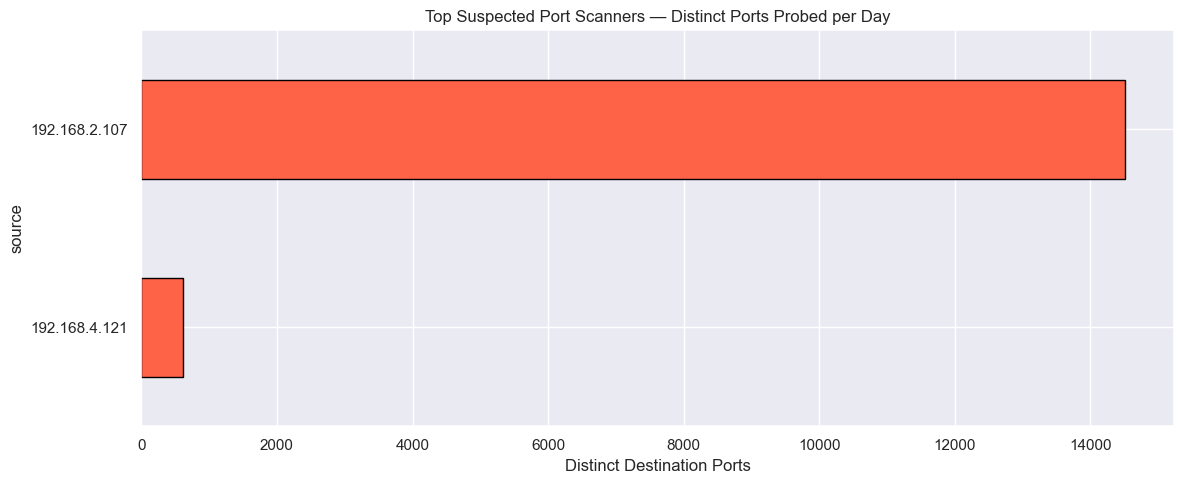

In [22]:
# ─── 4a-1: Stealthy Port Scan Detection ───────────────────────────────────
print('=' * 55)
print('SECTION 4 — DEEP SECURITY THREAT ANALYSIS')
print('=' * 55)

# A port scan = source IP probing many distinct destination ports.
# 'Stealthy' = spread over time (one probe per minute rather than all at once)
# to avoid triggering rate-based IDS rules.
#
# We detect by grouping per (source, day) and counting:
#   - distinct_ports   : how many unique destination ports were contacted
#   - distinct_targets : how many unique destination IPs were contacted
# Both must exceed 2σ to be flagged — probing many ports on many hosts
# is the clearest signal of reconnaissance.
port_scan = (df.groupby(['source', 'date'])
               .agg(
                   distinct_ports   = ('destinationPort', 'nunique'),
                   distinct_targets = ('destination',     'nunique'),
                   total_flows      = ('source',          'count'),
                   protocols_used   = ('protocolName',    'nunique'),
                   duration_span    = ('duration',        'sum')
               )
               .reset_index())

scan_thresh_ports   = port_scan['distinct_ports'].mean()   + 2 * port_scan['distinct_ports'].std()
scan_thresh_targets = port_scan['distinct_targets'].mean() + 2 * port_scan['distinct_targets'].std()

# An IP must exceed BOTH thresholds — this reduces false positives
# (a web server contacts many IPs on port 80, but that's not a scan)
port_scan['is_scanner'] = (
    (port_scan['distinct_ports']   > scan_thresh_ports) &
    (port_scan['distinct_targets'] > scan_thresh_targets)
)

scanners = port_scan[port_scan['is_scanner']].sort_values('distinct_ports', ascending=False)

print(f'\n[Port Scan] Port threshold   : {scan_thresh_ports:.1f}')
print(f'[Port Scan] Target threshold : {scan_thresh_targets:.1f}')
print(f'[Port Scan] Suspected scanners: {len(scanners)}')
print()
print(scanners[['source', 'date', 'distinct_ports',
                'distinct_targets', 'total_flows']].head(10).to_string(index=False))

# ── Label validation ──────────────────────────────────────────────────────
if 'Label' in df.columns and len(scanners) > 0:
    scanner_labels = df[df['source'].isin(scanners['source'])]['Label'].value_counts()
    print(f'\nLabel distribution of flagged scanner IPs:')
    print(scanner_labels.to_string())

# ── Visualisation ─────────────────────────────────────────────────────────
if len(scanners) > 0:
    top_scanners = scanners.groupby('source')['distinct_ports'].max().nlargest(10)
    top_scanners.plot(kind='barh', color='tomato', edgecolor='black')
    plt.title('Top Suspected Port Scanners — Distinct Ports Probed per Day')
    plt.xlabel('Distinct Destination Ports')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

[Slow DDoS] Windows with sustained 3hr traffic increase: 13

        hour_window  flow_count  total_bytes  rolling_mean_bytes
2010-06-12 06:00:00       20166    751209194        4.718454e+08
2010-06-13 10:00:00       67952   2356769418        1.032769e+09
2010-06-15 09:00:00       45234   1384864272        7.881230e+08
2010-06-16 09:00:00       21328    631765211        4.747515e+08
2010-06-16 10:00:00       40588   1408699470        8.202316e+08
2010-06-16 11:00:00       31081   1973102066        1.337856e+09
2010-06-17 04:00:00        5666    212467966        1.039815e+08
2010-06-17 05:00:00       42437   1104593002        4.577983e+08
2010-06-17 06:00:00       41241   1309432671        8.754979e+08
2010-06-17 07:00:00       44692   1542556345        1.318861e+09
2010-06-17 08:00:00       36498   1852842485        1.568277e+09
2010-06-17 18:00:00        9889    306874929        2.415101e+08
2010-06-17 22:00:00        5750    296919219        2.471291e+08


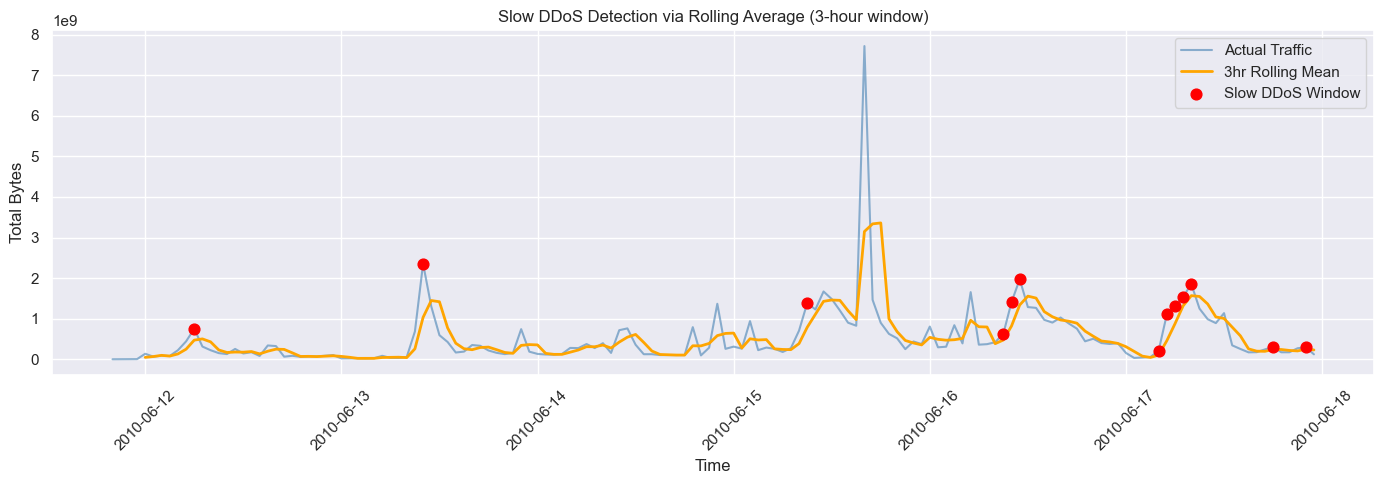

In [23]:
# ─── 4a-2: Slow DDoS Detection ────────────────────────────────────────────
# A slow DDoS doesn't create an obvious spike — instead, traffic rises
# gradually over hours, slowly exhausting server resources.
# Detection method: flag windows where traffic has increased for 3+ consecutive
# hours using a rolling boolean on the first-difference of bytes.

hourly_flows = (df.groupby('hour_window')
                  .agg(flow_count    = ('source',     'count'),
                       total_bytes   = ('totalBytes', 'sum'),
                       unique_sources = ('source',    'nunique'))
                  .reset_index()
                  .sort_values('hour_window'))

# Rolling mean provides a smoother trend line that's easier to read
hourly_flows['rolling_mean_bytes'] = hourly_flows['total_bytes'].rolling(3).mean()
hourly_flows['rolling_mean_flows'] = hourly_flows['flow_count'].rolling(3).mean()

# diff() gives the change from the previous window.
# If positive for 3 consecutive windows, traffic is consistently rising.
hourly_flows['bytes_increasing'] = hourly_flows['total_bytes'].diff() > 0

# A 'slow DDoS window' is one where the last 3 consecutive hours all showed
# increasing traffic — sustained growth, not a random fluctuation
hourly_flows['slow_ddos_flag'] = (
    hourly_flows['bytes_increasing'] &
    hourly_flows['bytes_increasing'].shift(1).fillna(False) &
    hourly_flows['bytes_increasing'].shift(2).fillna(False)
)

slow_ddos_windows = hourly_flows[hourly_flows['slow_ddos_flag']]
print(f'[Slow DDoS] Windows with sustained 3hr traffic increase: {len(slow_ddos_windows)}')
print()
print(slow_ddos_windows[['hour_window', 'flow_count',
                          'total_bytes', 'rolling_mean_bytes']].to_string(index=False))

# ── Visualisation ─────────────────────────────────────────────────────────
# Blue line = actual traffic; orange = 3hr rolling mean (smoothed trend);
# red dots = windows where slow DDoS pattern was detected
plt.figure(figsize=(14, 5))
plt.plot(hourly_flows['hour_window'], hourly_flows['total_bytes'],
         label='Actual Traffic', color='steelblue', alpha=0.6)
plt.plot(hourly_flows['hour_window'], hourly_flows['rolling_mean_bytes'],
         label='3hr Rolling Mean', color='orange', linewidth=2)
plt.scatter(slow_ddos_windows['hour_window'], slow_ddos_windows['total_bytes'],
            color='red', zorder=5, label='Slow DDoS Window', s=60)
plt.title('Slow DDoS Detection via Rolling Average (3-hour window)')
plt.xlabel('Time')
plt.ylabel('Total Bytes')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
# ─── 4a-3: IP Hopping Behaviour ───────────────────────────────────────────
# IP hopping = one attacker using many source IPs to hit the same destination
# port, cycling through addresses to evade per-IP rate limiting.
#
# Detection: find destination ports that receive connections from an abnormally
# large number of distinct source IPs within a single hour window.
port_sources = (df.groupby(['destinationPort', 'hour_window'])
                  .agg(distinct_sources = ('source', 'nunique'),
                       total_flows      = ('source', 'count'))
                  .reset_index())

ps_mean   = port_sources['distinct_sources'].mean()
ps_std    = port_sources['distinct_sources'].std()
ps_thresh = ps_mean + 2 * ps_std

ip_hop_ports = port_sources[
    port_sources['distinct_sources'] > ps_thresh
].sort_values('distinct_sources', ascending=False)

print(f'[IP Hopping] Threshold (mean + 2σ): {ps_thresh:.1f} distinct sources per port per hour')
print(f'[IP Hopping] Suspicious port-window combos: {len(ip_hop_ports)}')
print()
print(ip_hop_ports.head(10).to_string(index=False))

# Drill into the most suspicious port to see the rotating source IPs
if len(ip_hop_ports) > 0:
    top_port   = ip_hop_ports.iloc[0]['destinationPort']
    top_window = ip_hop_ports.iloc[0]['hour_window']
    rotating_ips = df[
        (df['destinationPort'] == top_port) &
        (df['hour_window']     == top_window)
    ]['source'].value_counts()
    print(f'\nSource IPs hitting port {top_port} during {top_window}:')
    print(rotating_ips.head(10).to_string())

[IP Hopping] Threshold (mean + 2σ): 13.5 distinct sources per port per hour
[IP Hopping] Suspicious port-window combos: 791

 destinationPort         hour_window  distinct_sources  total_flows
               0 2010-06-15 07:00:00               445          854
               0 2010-06-15 02:00:00               442          894
               0 2010-06-15 04:00:00               406          763
               0 2010-06-15 06:00:00               406          720
               0 2010-06-15 05:00:00               396          788
               0 2010-06-15 03:00:00               382          668
               0 2010-06-15 08:00:00               363          553
               0 2010-06-15 01:00:00               303          337
               0 2010-06-14 22:00:00               181          192
               0 2010-06-14 23:00:00               149          154

Source IPs hitting port 0 during 2010-06-15 07:00:00:
source
190.160.2.50       10
122.162.41.94       8
92.224.99.208       7

### 4b — Malicious Payload Identification

We analyse the `sourcePayloadAsUTF` column for suspicious content and use flow-level statistics to identify C2 (command-and-control) beaconing patterns.

In [25]:
# ─── 4b-1: Payload Analysis ───────────────────────────────────────────────
# The sourcePayloadAsUTF column contains the human-readable payload content.
# Short payloads (<20 chars) on non-standard ports may be C2 command packets.
# We also scan for known-suspicious keywords (shell commands, download tools).

df['has_payload'] = df['sourcePayloadAsUTF'].notna() & (df['sourcePayloadAsUTF'].str.len() > 0)
payload_flows = df[df['has_payload']].copy()

print(f'Flows with payload data: {len(payload_flows):,}')

if len(payload_flows) > 0:
    payload_flows['payload_len'] = payload_flows['sourcePayloadAsUTF'].str.len()
    short_payload = payload_flows[payload_flows['payload_len'] < 20]

    print(f'Short payloads (<20 chars): {len(short_payload):,}')
    print()
    print(short_payload[['source', 'destination', 'destinationPort',
                          'protocolName', 'payload_len',
                          'sourcePayloadAsUTF']].head(10).to_string(index=False))

    # ── Keyword scanning for malicious command strings ─────────────────────
    # These keywords appear in exploitation payloads, reverse shells, and
    # download-and-execute attack chains.
    suspicious_keywords = [
        'cmd', 'exec', 'shell', 'powershell', 'wget', 'curl',
        'base64', 'eval', '/bin/', 'nc ', '/etc/passwd', 'whoami'
    ]
    print('\n── Suspicious keyword hits in payload data ──')
    found_any = False
    for kw in suspicious_keywords:
        matches = payload_flows[
            payload_flows['sourcePayloadAsUTF'].str.contains(kw, case=False, na=False)
        ]
        if len(matches) > 0:
            print(f"  Keyword '{kw:12}': found in {len(matches):,} flows")
            found_any = True
    if not found_any:
        print('  No suspicious keywords detected in plaintext payloads.')

Flows with payload data: 888,802
Short payloads (<20 chars): 27,439

       source   destination  destinationPort protocolName  payload_len  sourcePayloadAsUTF
192.168.5.122 205.188.103.1               25       tcp_ip            4                QUIT
192.168.5.122   64.12.90.98               25       tcp_ip            4                QUIT
192.168.1.104 192.168.5.122               53       udp_ip           17   mwwwncbinlmnihgov
192.168.4.118 192.168.5.122               53       udp_ip           12        !wwwbox66com
192.168.2.111 192.168.5.122               53       udp_ip           14      ,wwwseonavicom
192.168.2.113 192.168.5.122               53       udp_ip           19 Kbugzillamozillaorg
192.168.2.108 192.168.5.122               53       udp_ip           10          1wwwsedode
192.168.2.108 192.168.5.122               53       udp_ip           10          2wwwsedode
192.168.3.115 192.168.5.122               53       udp_ip           19 wwwsimplescriptscom
192.168.2.112 192.168

In [26]:
# ─── 4b-2: C2 Beaconing Pattern Detection ────────────────────────────────
# Command-and-control (C2) traffic has distinctive characteristics:
#   1. Repetitive: many flows from same source to same destination
#   2. Small: beacon messages are short (heartbeat/status only)
#   3. Regular: automated beacons fire at fixed intervals (low std_interval)
#   4. Unusual port: legitimate traffic uses 80/443; malware avoids these
#
# We score each (source, destination, port) triplet against all four criteria.

# Well-known ports used by legitimate services — excluded from C2 detection
# to avoid false positives on regular web/email/DNS traffic
common_ports = {80, 443, 22, 21, 25, 53, 8080, 8443, 3389}

pair_timing = (df.groupby(['source', 'destination', 'destinationPort'])
                 .agg(
                     flow_count   = ('startDateTime', 'count'),
                     avg_bytes    = ('totalBytes',    'mean'),
                     # std_interval: standard deviation of time gaps between flows
                     # Low std = very regular timing = hallmark of automated beaconing
                     std_interval = ('startDateTime',
                                     lambda x: x.sort_values().diff()
                                                .dt.total_seconds()
                                                .std() if len(x) > 2 else np.nan)
                 )
                 .reset_index())

# Use the 25th percentile as thresholds — we want the bottom quartile
# of bytes and intervals (the smallest/most regular ones)
bytes_low_thresh    = pair_timing['avg_bytes'].quantile(0.25)
interval_low_thresh = pair_timing['std_interval'].quantile(0.25)

c2_candidates = pair_timing[
    (pair_timing['flow_count']   >= 5) &                              # repeated contact
    (pair_timing['avg_bytes']    <= bytes_low_thresh) &               # small payload
    (pair_timing['std_interval'] <= interval_low_thresh) &            # regular timing
    (~pair_timing['destinationPort'].isin(common_ports))              # non-standard port
].sort_values('flow_count', ascending=False)

print(f'[C2] Low-byte threshold      : {bytes_low_thresh:.1f} bytes')
print(f'[C2] Low-interval std        : {interval_low_thresh:.1f} seconds')
print(f'[C2] C2 candidate pairs      : {len(c2_candidates)}')
print()
print(c2_candidates.head(10).to_string(index=False))

[C2] Low-byte threshold      : 256.0 bytes
[C2] Low-interval std        : 300.0 seconds
[C2] C2 candidate pairs      : 145

       source   destination  destinationPort  flow_count  avg_bytes  std_interval
192.168.2.113 192.168.2.255              137        1097 252.295351    278.094046
192.168.1.101 192.168.1.255              137         922 153.370933    276.830162
192.168.4.118 192.168.4.255              137         867 111.169550    260.374358
192.168.1.103 192.168.1.255              137         858 243.020979    261.320900
192.168.2.106 192.168.2.255              137         849 113.413428    259.742600
192.168.1.105 192.168.1.255              138         842 246.935867    253.660271
192.168.4.120 192.168.4.255              138         842 248.222090    252.442884
192.168.1.104 192.168.1.255              138         842 246.935867    253.148813
192.168.2.106 192.168.2.255              138         840 247.000000    252.393201
192.168.2.109 192.168.2.255              138         840

### 4c — Threat Attribution and Risk Classification

All detected threats are consolidated into a unified registry and classified by risk level:
- 🔴 **High** — strong indicators of active attack or exploitation
- 🟡 **Medium** — suspicious but may be benign; requires investigation
- 🟢 **Low** — minor anomalies unlikely to cause immediate harm

In [27]:
# ─── 4c: Unified Threat Registry ──────────────────────────────────────────
# We collect all detected threats from every detection method above into
# a single structured list. Each entry records:
#   source_ip     : the IP(s) involved
#   threat_type   : what kind of attack this is
#   detail        : specific evidence from the data
#   risk_level    : High / Medium / Low
#   justification : why this risk level was assigned

threats = []

# ── Port Scanners → High risk ─────────────────────────────────────────────
# Reconnaissance is a precursor step to every network intrusion.
# An IP probing many ports/hosts is actively mapping the network for targets.
for _, row in scanners.head(20).iterrows():
    threats.append({
        'source_ip'    : row['source'],
        'threat_type'  : 'Port Scan',
        'detail'       : f"{row['distinct_ports']} ports, {row['distinct_targets']} targets on {row['date']}",
        'risk_level'   : 'High',
        'justification': 'Probing many ports/targets = network reconnaissance, precursor to exploitation'
    })

# ── Slow DDoS → High risk ─────────────────────────────────────────────────
# Gradual resource exhaustion is harder to stop than a spike attack because
# it doesn't trigger volume-based rate limiters.
for _, row in slow_ddos_windows.head(5).iterrows():
    threats.append({
        'source_ip'    : 'Multiple',
        'threat_type'  : 'Slow DDoS',
        'detail'       : f"Window: {row['hour_window']} — {row['flow_count']} flows, {row['total_bytes']:,} bytes",
        'risk_level'   : 'High',
        'justification': '3+ consecutive hours of traffic growth = sustained resource exhaustion attempt'
    })

# ── IP Hopping → Medium risk ──────────────────────────────────────────────
# Suggests coordinated evasion, but alone is not proof of exploitation.
for _, row in ip_hop_ports.head(5).iterrows():
    threats.append({
        'source_ip'    : 'Multiple (rotating)',
        'threat_type'  : 'IP Hopping',
        'detail'       : f"Port {row['destinationPort']} hit by {row['distinct_sources']} IPs in one window",
        'risk_level'   : 'Medium',
        'justification': 'Many IPs hitting same port in short window = coordinated evasion pattern'
    })

# ── C2 Beaconing → High risk ──────────────────────────────────────────────
# If a host is beaconing to a C2 server, it is already compromised.
# This is the most severe finding — requires immediate isolation.
for _, row in c2_candidates.head(10).iterrows():
    threats.append({
        'source_ip'    : row['source'],
        'threat_type'  : 'C2 Beaconing',
        'detail'       : (f"{row['source']} → {row['destination']}:{row['destinationPort']} "
                         f"({row['flow_count']} flows, avg {row['avg_bytes']:.0f} bytes)"),
        'risk_level'   : 'High',
        'justification': 'Periodic low-byte flows to non-standard port matches malware C2 beaconing pattern'
    })

# ── Long Duration Flows → Medium risk ────────────────────────────────────
# Could be a legitimate persistent connection (e.g., SSH session)
# or an exfiltration tunnel — needs manual investigation.
for _, row in long_connections.head(5).iterrows():
    threats.append({
        'source_ip'    : row['source'],
        'threat_type'  : 'Long Connection',
        'detail'       : f"{row['source']} → {row['destination']} for {row['duration']/3600:.1f} hours",
        'risk_level'   : 'Medium',
        'justification': 'Abnormally long connection may indicate persistent backdoor or data exfiltration'
    })

# ── Multi-Protocol IPs → Low risk ────────────────────────────────────────
# Unusual but not definitively malicious — could be a developer or admin host.
for _, row in multi_proto.head(5).iterrows():
    threats.append({
        'source_ip'    : row['source'],
        'threat_type'  : 'Multi-Protocol',
        'detail'       : f"{row['distinct_protocols']} protocols in one hour window",
        'risk_level'   : 'Low',
        'justification': 'Rapid protocol switching may indicate scanning or protocol tunnelling'
    })

# ── Burst Activity → Medium risk ─────────────────────────────────────────
# Sudden wake-up from inactivity is a common pattern for:
# (a) malware that sleeps to evade detection, then activates on a schedule
# (b) a compromised host receiving a remote command to begin exfiltration
for _, row in suspicious_bursts.head(5).iterrows():
    threats.append({
        'source_ip'    : row['source'],
        'threat_type'  : 'Burst Activity',
        'detail'       : f"Spike ratio {row['spike_ratio']:.1f}x above average activity",
        'risk_level'   : 'Medium',
        'justification': 'Sudden activity burst after quiet periods suggests a compromised host activating'
    })

# ── Build the threat dataframe ────────────────────────────────────────────
threat_df = pd.DataFrame(threats)

print('=' * 65)
print('THREAT REGISTRY')
print('=' * 65)
print(threat_df[['threat_type', 'risk_level', 'source_ip', 'detail']].to_string(index=False))

THREAT REGISTRY
    threat_type risk_level           source_ip                                                         detail
      Port Scan       High       192.168.2.107                       14509 ports, 19291 targets on 2010-06-15
      Port Scan       High       192.168.2.107                         4230 ports, 5044 targets on 2010-06-14
      Port Scan       High       192.168.4.121                          614 ports, 1244 targets on 2010-06-16
      Slow DDoS       High            Multiple   Window: 2010-06-12 06:00:00 — 20166 flows, 751,209,194 bytes
      Slow DDoS       High            Multiple Window: 2010-06-13 10:00:00 — 67952 flows, 2,356,769,418 bytes
      Slow DDoS       High            Multiple Window: 2010-06-15 09:00:00 — 45234 flows, 1,384,864,272 bytes
      Slow DDoS       High            Multiple   Window: 2010-06-16 09:00:00 — 21328 flows, 631,765,211 bytes
      Slow DDoS       High            Multiple Window: 2010-06-16 10:00:00 — 40588 flows, 1,408,699,470 

         NETWORK SECURITY RISK REPORT

EXECUTIVE SUMMARY
─────────────────
Total threats detected : 38
  🔴 High risk         : 18
  🟡 Medium risk       : 15
  🟢 Low risk          : 5

Dataset analysed       : 2,071,657 flows
Unique source IPs      : 2,478
Unique destination IPs : 34,555
Time range             : 2010-06-11 20:10:00 → 2010-06-17 23:58:00

🔴  HIGH RISK THREATS (18 detected)
───────────────────────────────────────────────────────
  Type   : Port Scan
  Source : 192.168.2.107
  Detail : 14509 ports, 19291 targets on 2010-06-15
  Why    : Probing many ports/targets = network reconnaissance, precursor to exploitation

  Type   : Port Scan
  Source : 192.168.2.107
  Detail : 4230 ports, 5044 targets on 2010-06-14
  Why    : Probing many ports/targets = network reconnaissance, precursor to exploitation

  Type   : Port Scan
  Source : 192.168.4.121
  Detail : 614 ports, 1244 targets on 2010-06-16
  Why    : Probing many ports/targets = network reconnaissance, precursor to explo

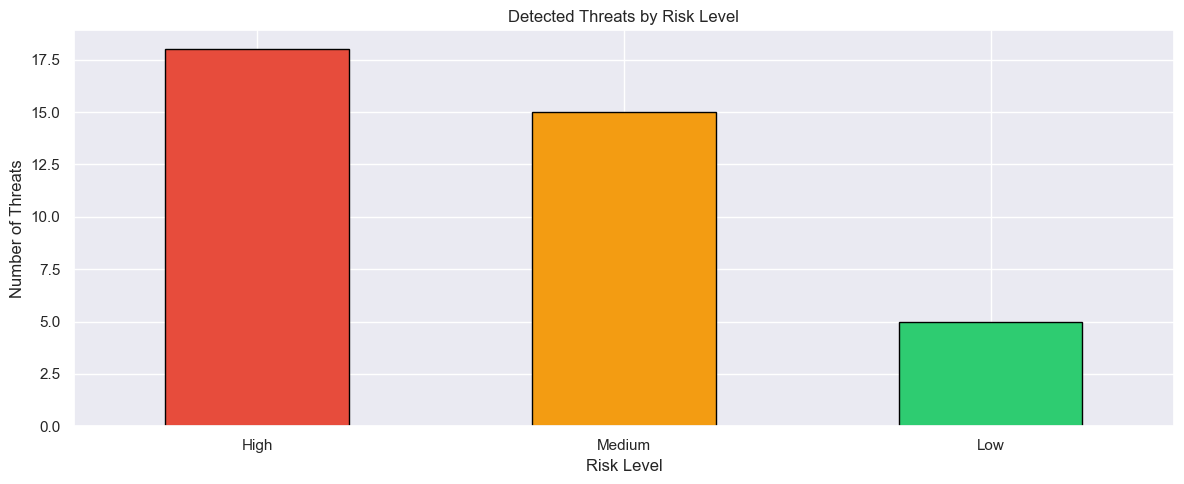

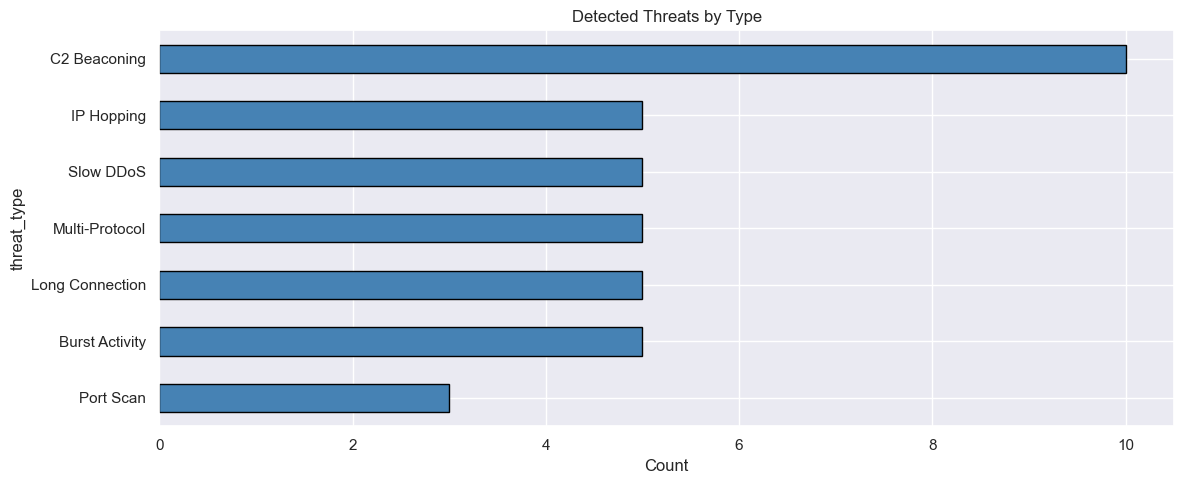

In [28]:
# ─── Final Risk Report ─────────────────────────────────────────────────────
# Produces a structured, human-readable security report summarising all
# findings from Sections 3 and 4. Suitable for inclusion in the PDF report.

high   = threat_df[threat_df['risk_level'] == 'High']
medium = threat_df[threat_df['risk_level'] == 'Medium']
low    = threat_df[threat_df['risk_level'] == 'Low']

print('=' * 65)
print('         NETWORK SECURITY RISK REPORT')
print('=' * 65)

print(f"""
EXECUTIVE SUMMARY
─────────────────
Total threats detected : {len(threat_df)}
  🔴 High risk         : {len(high)}
  🟡 Medium risk       : {len(medium)}
  🟢 Low risk          : {len(low)}

Dataset analysed       : {len(df):,} flows
Unique source IPs      : {df['source'].nunique():,}
Unique destination IPs : {df['destination'].nunique():,}
Time range             : {df['startDateTime'].min()} → {df['stopDateTime'].max()}
""")

for level, group, emoji in [('HIGH', high, '🔴'), ('MEDIUM', medium, '🟡'), ('LOW', low, '🟢')]:
    print(f'{emoji}  {level} RISK THREATS ({len(group)} detected)')
    print('─' * 55)
    for _, row in group.iterrows():
        print(f'  Type   : {row["threat_type"]}')
        print(f'  Source : {row["source_ip"]}')
        print(f'  Detail : {row["detail"]}')
        print(f'  Why    : {row["justification"]}')
        print()

print('=' * 65)
print('RECOMMENDATIONS')
print('─' * 55)
print('1. Immediately block/isolate all High risk source IPs')
print('2. Enable rate limiting on ports flagged by IP hopping analysis')
print('3. Deploy deep packet inspection on C2 candidate flows')
print('4. Set automated alerts for rolling traffic increases over 3 windows')
print('5. Review all long-duration connections for data exfiltration evidence')
print('=' * 65)

# ── Risk level distribution chart ─────────────────────────────────────────
# A quick visual summary of the threat breakdown by risk tier
risk_counts = threat_df['risk_level'].value_counts().reindex(['High', 'Medium', 'Low'])
colors = ['#e74c3c', '#f39c12', '#2ecc71']   # red, amber, green
risk_counts.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Detected Threats by Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Number of Threats')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Threat type breakdown chart ────────────────────────────────────────────
threat_type_counts = threat_df['threat_type'].value_counts()
threat_type_counts.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Detected Threats by Type')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()